# 🧠 Choosing the Right Model: Machine Learning vs. Deep Learning

**Developed by** SzuLun Huang · **Guided by** Eric Van Dusen · UC Berkeley Data Science

**What you'll do:** see when traditional machine learning is not enough, how neural networks learn, and how to pick a model for a task using an interactive decision map.

**Time:** core path about 30–45 minutes. Parts marked 🔵 Optional are extra.

> 🆘 **Stuck, or seeing a red error?** Open the **🆘 help box** just below. It takes about 30 seconds.

> ✋ **You never need to type or change any code.** Just click **Run** on a cell, or use the boxes and buttons that appear. The code is hidden on purpose.

<details>
<summary><b>📖 About this notebook (setup notes, roadmap, credits). Click to open.</b></summary>

**Notebook developed by** SzuLun Huang  
**Under the guidance of** Eric Van Dusen  
**UC Berkeley, Data Science**

---

<details>
<summary><b>📌 Compatibility and setup notes (click to open)</b></summary>

### 📌 Compatibility
This notebook runs on **JupyterHub** and **Google Colab**.

> **Before you begin:**
> - Prefer **Run All** once so all explanations and interactive widgets load
> - After loading, the **quiz**, **decision map**, **Move the Edge**, and **convolution lab** are independent — answer, click, or drag sliders in place
> - **Core path ≈ 30–45 minutes** (full exploration can take longer)

</details>

---

<details>
<summary><b>⏱️ Core vs optional parts (click to open)</b></summary>

### ⏱️ Core vs Optional

| Tag | Meaning |
|------|------|
| **🟢 Core** | Recommended for a typical class session (≈ 30–45 min) |
| **🔵 Optional deep dive** | Explore if you have time; not required to finish everything in one sitting |

</details>

**Suggested core path:** Part 1 quiz → Part 2 basics & training loop → Part 3 decision map trunk (you need not open every sub-page) → Part 5 model selection & short case  

**Optional deep dives:** CNN building blocks, equivariance / Move the Edge, convolution code lab, full model-family notes, cross-domain examples

**You will:**
1. Use scenario questions to see when traditional ML is not enough
2. Build intuition for how neural nets learn
3. Walk an interactive **decision map** to pick a model direction for a task
4. Meet the main model families — strengths, limits, and where they sit today
5. Run a tiny convolution calculation and finish an open-ended case

</details>


<!--stuck-guide-->
<details>
<summary><b>🆘 Stuck, or seeing a red error? Click here for help</b></summary>

### If something looks wrong, try this first

Don't worry: **you can't break anything.** Almost every problem is fixed by running the notebook again from the top.

**1️⃣ Run everything again, in order**

**JupyterHub:** choose **Kernel → Restart Kernel and Run All Cells…** (safest) or **Run → Run All Cells**.

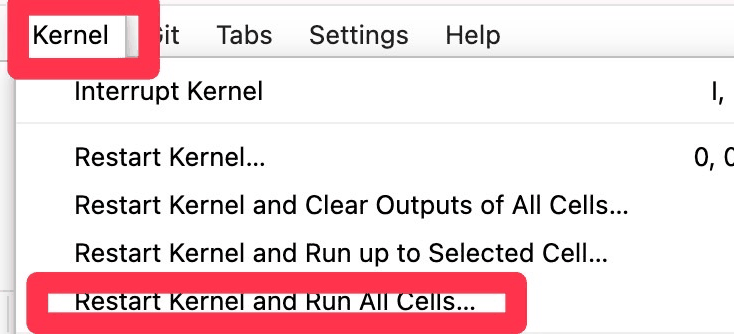

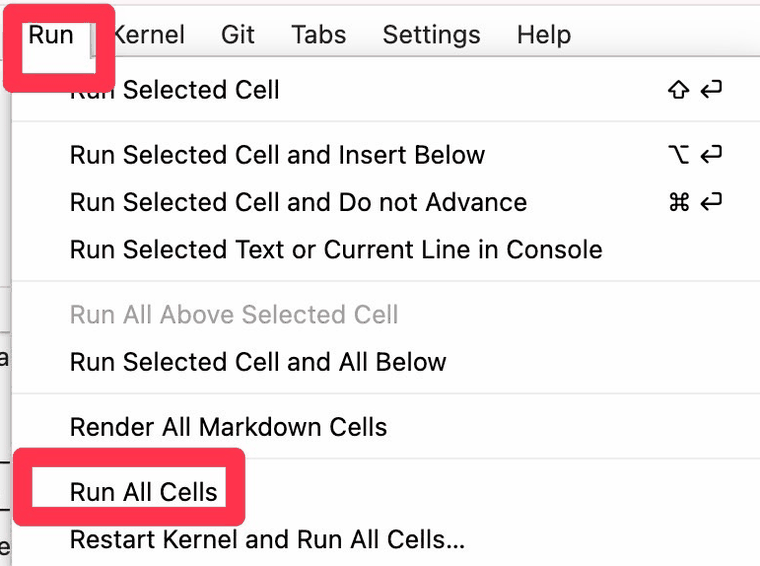

**Google Colab:** choose **Runtime → Run all**.

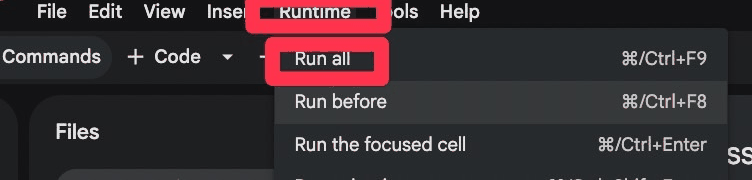

**2️⃣ See a red error message?**

It usually means a step above was skipped, or cells were run out of order. That is not your fault. Run everything again from the top (step 1).

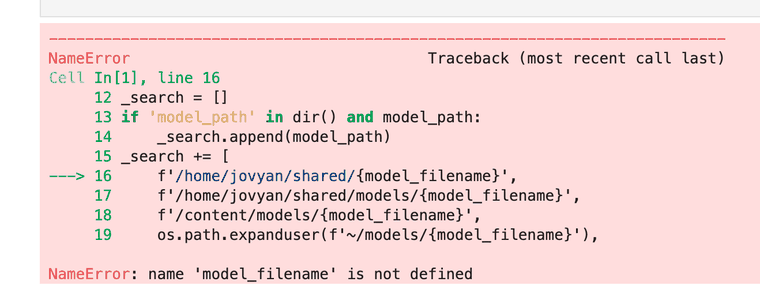

**3️⃣ Did a code cell open up?**

Most code is hidden on purpose. If a cell expanded when you clicked it, you do not need to read or change it. Click the blue bar on its left (JupyterHub) to collapse it, then keep going. Please do not re-run code cells one by one; run everything from the top instead.

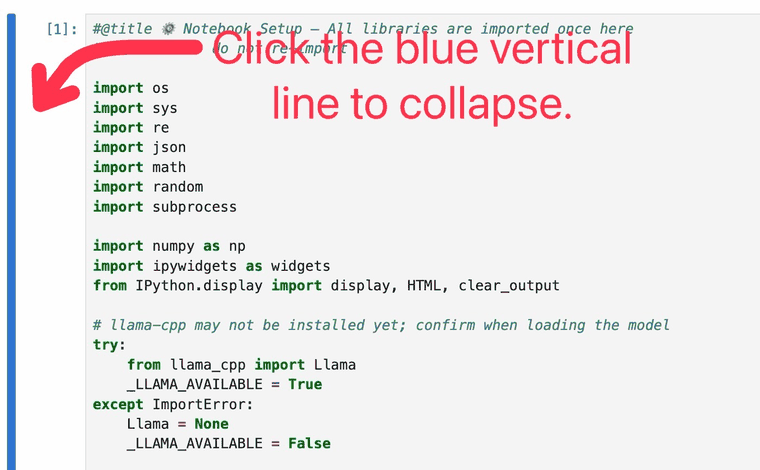

**4️⃣ What does `[*]` mean?**

The cell is still running. Wait until it turns into a number such as `[3]`. Loading the language model can take a minute or two.

![A cell that is still running shows [*]](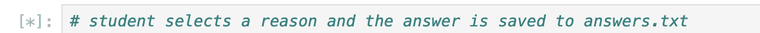)

**5️⃣ Still stuck?**

Refresh the page and run everything again from the top. If it still does not work, tell your instructor which step you are on.

**6️⃣ Need to start over with a fresh copy?**

Only do this if the notebook is broken after you typed in or changed a code cell.

- **JupyterHub:** close this notebook’s tab. In the file list on the left, right-click this notebook and choose **Delete** (this deletes only your copy). Then click your instructor’s link again and a fresh copy will appear.
- **Google Colab:** close the tab and open your instructor’s link again. It opens a fresh copy.

Your answers are saved separately, so starting over will not erase them.

</details>

In [ ]:
#@title 🔬 Helper functions (run once)
import uuid, json, os, time, threading, html as _html
import ipywidgets as widgets
from IPython.display import display, HTML

_FORM_URL = "https://docs.google.com/forms/d/e/1FAIpQLSfj6fQ0qPa9oQ-n8qbtRAb2h8qJzLo0eBPiwz7dveIV0BMAdw/formResponse"
_ENTRY = {"session": "entry.817703458", "notebook": "entry.1518647579", "version": "entry.2104588287", "step": "entry.1456104355", "choice": "entry.1167752725", "reason": "entry.2099469986", "confidence": "entry.1190945772", "extra": "entry.1044793006"}
NOTEBOOK_ID = "DL_Map_Explorer"
NOTEBOOK_VERSION = "2026-10-v4"
def _get_session():
    """Random code (not linked to your name). Reused for a few hours so a restart keeps the same code."""
    p = os.path.expanduser("~/.notebook_session_" + NOTEBOOK_ID)
    try:
        if os.path.exists(p):
            sid, ts = open(p).read().strip().split("|")
            if time.time() - float(ts) < 6 * 3600:
                return sid
    except Exception:
        pass
    sid = uuid.uuid4().hex[:8]
    try:
        open(p, "w").write(sid + "|" + str(time.time()))
    except Exception:
        pass
    return sid
if "SESSION_ID" not in globals():
    SESSION_ID = _get_session()
SHARE_ANSWERS = True

def _save_local_copy(rec):
    try:
        with open(os.path.expanduser("~/notebook_responses.jsonl"), "a", encoding="utf-8") as f:
            f.write(json.dumps(rec, ensure_ascii=False) + "\n")
    except Exception:
        pass

def _post(rec):
    try:
        import requests
        data = {_ENTRY[k]: str(rec.get(k, "")) for k in _ENTRY}
        for _ in range(2):
            try:
                if requests.post(_FORM_URL, data=data, timeout=10).ok:
                    return True
            except Exception:
                pass
    except Exception:
        pass
    return False

def log_event(step, choice="", reason="", confidence="", extra="", wait=False):
    """Returns True (sent), False (could not send) or None (sharing is off)."""
    rec = {"session": SESSION_ID, "notebook": NOTEBOOK_ID, "version": NOTEBOOK_VERSION, "step": step,
           "choice": choice, "reason": reason, "confidence": confidence, "extra": extra}
    _save_local_copy(rec)
    if not SHARE_ANSWERS:
        return None
    if wait:
        return _post(rec)
    threading.Thread(target=_post, args=(rec,), daemon=True).start()
    return True

_CONF = ["— choose —", "1 (not sure at all)", "2", "3", "4", "5 (very sure)"]
def _val(v):
    return "" if str(v).startswith("—") else str(v)
def _esc(s):
    return _html.escape(str(s)).replace("\n", "<br>")
def _box(inner, color="#166534", bg="#f0fdf4"):
    return HTML(f'<div style="border-left:4px solid {color};background:{bg};padding:10px 14px;'
                f'border-radius:6px;max-width:640px;font-family:sans-serif;font-size:14px;color:#111">{inner}</div>')
def _note(ok):
    if ok is None:
        return "Your answer stays in this notebook only (you chose not to send answers)."
    return "Sent anonymously. A copy also stays in this notebook." if ok else \
           "Could not send right now, but your answer is kept here in this notebook."

def choose_and_justify(step, options, reason_label="Why? Explain your thinking.", extra=""):
    choice_w = widgets.Dropdown(options=["— choose —"] + list(options), description="Your choice:",
                                style={"description_width": "95px"}, layout=widgets.Layout(width="560px"))
    reason_w = widgets.Textarea(placeholder=reason_label, layout=widgets.Layout(width="640px", height="120px"))
    conf_w = widgets.Dropdown(options=_CONF, description="How sure are you?",
                              style={"description_width": "140px"}, layout=widgets.Layout(width="360px"))
    btn = widgets.Button(description="Submit my answer", button_style="primary")
    status = widgets.HTML("")
    display(widgets.VBox([choice_w, reason_w, conf_w, widgets.HBox([btn, status])]))
    receipt = display(HTML(""), display_id=True)
    def _on(_):
        c, r, k = _val(choice_w.value), reason_w.value.strip(), _val(conf_w.value)
        if not (c and r and k):
            status.value = '<span style="color:#b45309">&nbsp;Please choose an option, write a short reason, and say how sure you are.</span>'
            return
        btn.disabled = True
        status.value = "&nbsp;Saving…"
        ok = log_event(step, choice=c, reason=r, confidence=k[0], extra=extra, wait=True)
        status.value = ""
        receipt.update(_box("<b>Your recorded answer</b><br>"
                            f"<b>Choice:</b> {_esc(c)}<br><b>Reason:</b> {_esc(r)}<br>"
                            f"<b>How sure:</b> {_esc(k)}<br><span style='color:#555;font-size:12px'>{_note(ok)}</span>"))
    btn.on_click(_on)

def quick_predict(step, options, answer=None, extra=""):
    choice_w = widgets.Dropdown(options=["— choose —"] + list(options), description="My prediction:",
                                style={"description_width": "110px"}, layout=widgets.Layout(width="520px"))
    conf_w = widgets.Dropdown(options=_CONF, description="How sure?",
                              style={"description_width": "80px"}, layout=widgets.Layout(width="300px"))
    btn = widgets.Button(description="Lock in my prediction", button_style="primary")
    status = widgets.HTML("")
    display(widgets.VBox([choice_w, conf_w, widgets.HBox([btn, status])]))
    receipt = display(HTML(""), display_id=True)
    def _on(_):
        c, k = _val(choice_w.value), _val(conf_w.value)
        if not c:
            status.value = '<span style="color:#b45309">&nbsp;Pick an option first.</span>'
            return
        btn.disabled = True
        ex = extra
        if answer is not None:
            ex = (extra + ";" if extra else "") + "correct=" + str(c == list(options)[answer])
        ok = log_event(step, choice=c, confidence=k[:1], extra=ex)
        receipt.update(_box(f"<b>Your prediction:</b> {_esc(c)}" + (f" &nbsp;(<b>how sure:</b> {_esc(k)})" if k else "") +
                            "<br><span style='color:#555;font-size:12px'>Now read on and check it. "
                            "Being wrong here is useful, it is how you learn.</span>"))
    btn.on_click(_on)


_RATE = ["— choose —", "1 (not at all)", "2", "3", "4", "5 (very well)"]
_AGREE = ["— choose —", "1 (strongly disagree)", "2", "3", "4", "5 (strongly agree)"]
def check_block(phase, mcq=None, rating=None, scenario=None, helpful=None):
    """phase = 'PRE' (no feedback) or 'POST' (feedback on multiple-choice). mcq may be one dict or a list of dicts."""
    phase = phase.upper()
    W = widgets
    lay = lambda w: W.Layout(width=w)
    mcqs = [] if not mcq else (list(mcq) if isinstance(mcq, (list, tuple)) else [mcq])
    items, n = [], 0
    head = ("🧭 Before you start: a quick check" if phase == "PRE" else "✅ Check what you learned")
    sub = ("<b>It is completely OK if you don't know the answers.</b> This is not a test and nothing is graded. "
           "We just want to see how your thinking changes after you finish the notebook, so please give your honest best guess "
           "(or choose “I don't know yet”). "
           "You will get the correct answers at the end of the notebook. It takes about 2 minutes." if phase == "PRE" else
           "Same kind of questions as at the start. Answering is optional and nothing is graded.")
    items.append(W.HTML(f"<h3 style='margin:4px 0'>{head}</h3><div style='color:#444;max-width:640px'>{sub}</div>"))
    if phase == "PRE":
        items.append(W.HTML(_notice_widget().data))
    g, mq = {}, []
    for m in mcqs:
        n += 1
        q = W.Dropdown(options=["— choose —"] + list(m["options"]), layout=lay("640px"))
        c = W.Dropdown(options=_CONF, description="How sure are you?", style={"description_width": "140px"}, layout=lay("360px"))
        mq.append((m, q, c))
        items += [W.HTML(f"<b>{n}. {m['q']}</b>"), q, c]
    if rating:
        n += 1
        g["rt"] = W.Dropdown(options=_RATE, description="My rating:", style={"description_width": "90px"}, layout=lay("320px"))
        items += [W.HTML(f"<b>{n}. {rating}</b>"), g["rt"]]
    if scenario:
        n += 1
        g["sc"] = W.Dropdown(options=["— choose —"] + list(scenario["options"]), layout=lay("640px"))
        g["sr"] = W.Textarea(placeholder=scenario.get("reason_label", "Why?"), layout=W.Layout(width="640px", height="90px" if phase == "PRE" else "120px"))
        items += [W.HTML(f"<b>{n}. {scenario['prompt']}</b>"), g["sc"], g["sr"]]
    if helpful:
        n += 1
        g["hr"] = W.Dropdown(options=_AGREE, layout=lay("320px"))
        g["ha"] = W.Dropdown(options=["— choose —"] + list(helpful["activities"]), layout=lay("640px"))
        g["hw"] = W.Textarea(placeholder="Why? (optional)", layout=W.Layout(width="640px", height="70px"))
        items += [W.HTML(f"<b>{n}. This notebook helped me understand {helpful['topic']}.</b>"), g["hr"],
                  W.HTML("<b>&nbsp;&nbsp;Which part helped you most?</b>"), g["ha"], g["hw"]]
    btn = W.Button(description="Submit", button_style="primary")
    status = W.HTML("")
    items.append(W.HBox([btn, status]))
    display(W.VBox(items))
    receipt = display(HTML(""), display_id=True)

    def _on(_):
        miss = []
        for i, (m, q, c) in enumerate(mq, 1):
            if not (_val(q.value) and _val(c.value)): miss.append(f"question {i} (choice and how sure)")
        if rating and not _val(g["rt"].value): miss.append("your rating")
        if scenario and not (_val(g["sc"].value) and g["sr"].value.strip()): miss.append("the scenario question (choice and a short reason)")
        if helpful and not (_val(g["hr"].value) and _val(g["ha"].value)): miss.append("the last question (rating and which part helped)")
        if miss:
            status.value = '<span style="color:#b45309">&nbsp;Please complete: ' + ", ".join(miss) + ".</span>"
            return
        btn.disabled = True
        status.value = "&nbsp;Saving…"
        recs, shown, fb = [], [], ""
        for i, (m, q, c) in enumerate(mq, 1):
            cv, k = _val(q.value), _val(c.value)
            ok_ans = (cv == list(m["options"])[m["answer"]])
            recs.append(dict(step=phase + ("-mcq" if i == 1 else f"-mcq{i}"), choice=cv, confidence=k[0], extra=f"correct={ok_ans};topic={m.get('topic','')}"))
            shown.append(f"<b>Question {i}:</b> {_esc(cv)} (how sure: {_esc(k)})")
            if phase == "POST":
                _idk = cv.startswith("I don't know")
                fb += (f"<br>Q{i}: ✅ <b>Correct.</b> " if ok_ans else (f"<br>Q{i}: That's OK. " if _idk else f"<br>Q{i}: ❌ <b>Not quite.</b> ") + "The best answer is: "
                       + _esc(list(m["options"])[m["answer"]]) + ". ") + _esc(m.get("explain", ""))
        if rating:
            r = _val(g["rt"].value)
            recs.append(dict(step=phase + "-rating", choice=r[0], extra=f"topic={mcqs[0].get('topic','') if mcqs else ''}"))
            shown.append(f"<b>Self-rating:</b> {_esc(r)}")
        if scenario:
            cv, t = _val(g["sc"].value), g["sr"].value.strip()
            recs.append(dict(step=scenario["step"], choice=cv, reason=t))
            shown.append(f"<b>Your choice:</b> {_esc(cv)}<br><b>Your reason:</b> {_esc(t)}")
        if helpful:
            hr, ha, hw = _val(g["hr"].value), _val(g["ha"].value), g["hw"].value.strip()
            recs.append(dict(step="POST-helpful", choice=hr[0]))
            recs.append(dict(step="POST-helpful-part", choice=ha, reason=hw))
            shown.append(f"<b>Helpful:</b> {_esc(hr)}<br><b>Most helpful part:</b> {_esc(ha)}" + (f"<br><b>Why:</b> {_esc(hw)}" if hw else ""))
        results = []
        def _one(rec):
            results.append(log_event(wait=True, **rec))
        th = [threading.Thread(target=_one, args=(r,), daemon=True) for r in recs]
        for t_ in th: t_.start()
        for t_ in th: t_.join(timeout=25)
        status.value = ""
        ok = (None if (results and all(x is None for x in results)) else (len(results) == len(recs) and all(results)))
        later = "<br><i>Thanks! You will see the same kind of questions at the end of the notebook, together with the correct answers.</i>" if phase == "PRE" else ""
        receipt.update(_box("<b>Your recorded answers</b><br>" + "<br>".join(shown) + fb + later +
                            f"<br><span style='color:#555;font-size:12px'>{_note(ok)}</span>"))
    btn.on_click(_on)

def one_liner(step, label="What surprised you most, or what is still unclear? (optional)"):
    text_w = widgets.Textarea(placeholder=label, layout=widgets.Layout(width="640px", height="70px"))
    btn = widgets.Button(description="Send (optional)", button_style="")
    display(widgets.VBox([text_w, btn]))
    receipt = display(HTML(""), display_id=True)
    def _on(_):
        t = text_w.value.strip()
        if not t:
            return
        btn.disabled = True
        ok = log_event(step, reason=t, wait=True)
        receipt.update(_box(f"<b>Your note:</b> {_esc(t)}<br><span style='color:#555;font-size:12px'>{_note(ok)}</span>"))
    btn.on_click(_on)

def _notice_widget():
    return (_box("<b>🔒 About the questions and quizzes in this notebook.</b> Your answers are sent anonymously "
                 "(a random code, no name or email) to help improve these notebooks. Nothing is graded, and answering "
                 "the “explain your thinking” questions is optional."
                 "<details style='margin-top:6px'><summary style='cursor:pointer'>More about how answers are recorded</summary>"
                 "<div style='margin-top:6px'>Some activities ask you to choose an answer and explain your thinking. There are no right or wrong "
                 "answers to those questions. The quiz questions also record which option you picked and whether it was correct. "
                 "A copy of what you submit also stays in your notebook.</div></details>",
                 color="#1d4ed8", bg="#eff6ff"))


In [ ]:
#@title 🧭 Before you start
# Safety check: stops with a friendly hint if an earlier step was skipped.
if any(_n not in globals() for _n in ("check_block",)): raise type('RunFromTop', (Exception,), {'_render_traceback_': lambda self: ['⚠️ A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.']})('A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.')
check_block("PRE", mcq=[{'topic': 'model-choice', 'q': 'A bank has a spreadsheet with 100,000 customers (age, income, account balance) and wants to predict who will leave. What would you try first?', 'options': ['A. A simple, standard method that works well on tables', 'B. The biggest, most advanced AI model available', 'C. A model that generates images', 'D. A model that generates text', "I don't know yet"], 'answer': 0, 'explain': 'For rows-and-columns data, a simple traditional method is usually the best first step; bigger models are not automatically better.'}], rating='How well do you understand how to choose a type of model for a task?', scenario={'step': 'PRE-scenario', 'prompt': 'You need to sort 20,000 customer-support emails into 5 topics. What would you try first?', 'options': ['Keyword rules', 'Traditional ML on text features', 'A Transformer-based language model', 'I would need more information first'], 'reason_label': 'In one sentence, why?'})

In [1]:
#@title ⚙️ Notebook Setup - Import Libraries

# Notebook Setup — run this cell first
# All library imports are centralized here.

import random
import numpy as np
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

print("✅ Libraries loaded (numpy, ipywidgets, random).")


✅ Libraries loaded (numpy, ipywidgets, random).


## 🗺️ Build a Thinking Path First
**🟢 Core**

The goal of this notebook is not to memorize model names, but to build this habit:

> **Problem / data → what capability is needed → which model family fits → what are the limits**

> 💬 **Zoey:** “So image means CNN — just memorize that?”  
> **HAC:** “Not yet. CNNs matter a lot, but modern vision also uses Vision Transformers. We learn *why*, not slogans.”


## 🧭 Part 1: When Is Traditional Machine Learning Not Enough?
**🟢 Core**

Before diving into deep learning, test your intuition with a few realistic scenarios.  
For each question, decide: **Is traditional ML enough, or do you really need deep learning?**

<div style="text-align:center; margin:14px 0;"></div>

**Here is a quick comparison to start with: tabular data often starts with traditional ML, whereas image, sequence, and generative tasks are much more likely to benefit from deep learning. Treat this as a rule of thumb, not a hard rule.**


In [8]:
#@title Part 1: Scenario Quiz — When Do You Need Deep Learning?
# Safety check: stops with a friendly hint if an earlier step was skipped.
if any(_n not in globals() for _n in ("random", "widgets",)): raise type('RunFromTop', (Exception,), {'_render_traceback_': lambda self: ['⚠️ A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.']})('A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.')

# Larger question bank; each run samples 4 questions
quiz_bank = [
    {
        "question": "You want to predict house price from floor area. The data is a clean table (area, rooms, age, district). The best fit is:",
        "options": [
            "A. Traditional machine learning (e.g., linear regression or decision trees)",
            "B. Deep learning is required"
        ],
        "correct": 0,
        "explanation": "Structured tabular features already have clear meaning (area, rooms). Traditional ML is usually enough — and more efficient and interpretable. You do not need deep learning."
    },
    {
        "question": "You want the computer to look at a photo and decide cat vs dog. The input is raw pixels. The best fit is:",
        "options": [
            "A. Traditional machine learning",
            "B. Deep learning is needed"
        ],
        "correct": 1,
        "explanation": "A photo is hundreds of thousands of pixels. Nobody can hand-write rules like “this pixel pattern = cat ear.” Traditional ML needs human feature engineering; images are too complex for that. Deep learning’s strength is learning hierarchical features from raw pixels."
    },
    {
        "question": "You have a few hundred labeled emails and want to detect spam. For this task:",
        "options": [
            "A. Traditional ML can work well",
            "B. Only deep learning can work"
        ],
        "correct": 0,
        "explanation": "Simple text classification with bag-of-words or TF-IDF often works with traditional ML. Deep learning shines when scale and deep semantic understanding matter (e.g., modern LLMs). Need for DL is a spectrum, not a binary."
    },
    {
        "question": "You want a model to generate a realistic face image (not classify existing ones). The best fit is:",
        "options": [
            "A. Traditional machine learning",
            "B. Deep learning (generative models)"
        ],
        "correct": 1,
        "explanation": "Generating high-dimensional content (especially images) is nearly impossible with classical ML. Tasks like this need deep generative models such as GANs, VAEs, or modern Diffusion models."
    },
    {
        "question": "A bank wants to flag possible fraud from past transactions (amount, time, place, device) — mostly tabular features. A sensible start is:",
        "options": [
            "A. Build a strong traditional-ML baseline first",
            "B. Deep learning is the only useful option"
        ],
        "correct": 0,
        "explanation": "Risk tasks often stay tabular; classical ML or gradient-boosted trees are a strong first step. Deep learning can be used later, but should not be the default first instinct."
    },
    {
        "question": "Medical imaging: detect pneumonia from X-rays. Input is the image itself. For this task:",
        "options": [
            "A. Traditional ML is usually enough",
            "B. Deep learning is more common (e.g., CNN / ViT)"
        ],
        "correct": 1,
        "explanation": "Medical images are high-dimensional and unstructured; hand-designing “what a lesion looks like” is hard. Deep learning is often the right direction — with care for data size, label quality, and clinical validation."
    },
    {
        "question": "You have only 200 customer rows with clear numeric/categorical columns to predict renewal. You should:",
        "options": [
            "A. Prefer simple, interpretable traditional models",
            "B. Train a large deep network immediately"
        ],
        "correct": 0,
        "explanation": "With tiny structured data, complex deep models overfit easily and are harder to explain. Start simple."
    },
    {
        "question": "Speech-to-text (audio → text). For this task:",
        "options": [
            "A. Traditional ML is always enough",
            "B. Modern systems mostly rely on deep learning"
        ],
        "correct": 1,
        "explanation": "Raw audio is high-dimensional unstructured signal; modern ASR is almost entirely deep-model based."
    },
    {
        "question": "Recommender: you have user–item interaction tables (who clicked/bought what). A reasonable first try is usually:",
        "options": [
            "A. Collaborative filtering / matrix factorization and similar classical methods",
            "B. Jump straight to a large deep generative model"
        ],
        "correct": 0,
        "explanation": "Recommenders often start with classical methods or shallow models. Deep learning can add value later, but is not the only starting point."
    },
    {
        "question": "Generate a new product image from a text description. For this task:",
        "options": [
            "A. A classical regression model is enough",
            "B. You need deep generative models"
        ],
        "correct": 1,
        "explanation": "Text-to-image is a classic deep generative task; modern directions include Diffusion and Transformer-based generators."
    },
]

N_QUIZ = 4
quiz_questions = random.sample(quiz_bank, N_QUIZ)

current_q = 0
score = 0

question_label = widgets.HTML(value="")
options_widget = widgets.RadioButtons(options=[], layout=widgets.Layout(width="720px"))
submit_btn = widgets.Button(description="Submit", button_style="primary", disabled=True)
next_btn = widgets.Button(description="Next →", button_style="info", disabled=True)
feedback_area = widgets.HTML(value="")
progress_label = widgets.HTML(value="")

def on_option_change(change):
    submit_btn.disabled = (change["new"] is None)

options_widget.observe(on_option_change, names="value")

def show_question():
    global current_q
    q = quiz_questions[current_q]
    question_label.value = (
        f"<h3>Question {current_q+1} / {len(quiz_questions)}</h3>"
        f"<p style='color:#64748b; font-size:13px'>(Randomly sampled from a bank of {len(quiz_bank)} questions)</p>"
        f"<p style='font-size:15px'>{q['question']}</p>"
    )
    options_widget.options = q["options"]
    options_widget.value = None
    submit_btn.disabled = True
    feedback_area.value = ""
    next_btn.disabled = True
    progress_label.value = f"<p style='color:#334155; font-weight:600'>Score so far: {score} / {current_q}</p>"

def on_submit(b):
    global score, current_q
    if options_widget.value is None:
        feedback_area.value = "<p style='color:orange'>Please select an answer first</p>"
        return
    selected_idx = options_widget.options.index(options_widget.value)
    q = quiz_questions[current_q]
    if 'log_event' in globals():
        log_event(f"A-scenario-q{current_q+1}", choice=str(selected_idx+1), extra=f"correct={selected_idx == q['correct']}")
    if selected_idx == q["correct"]:
        score += 1
        feedback_area.value = (
            f"<div style='color:#14532d; font-weight:bold; margin-top:8px; padding:12px; "
            f"background:#dcfce7; border-radius:8px; border:1px solid #86efac'>"
            f"✅ Correct! {q['explanation']}</div>"
        )
    else:
        feedback_area.value = (
            f"<div style='color:#7f1d1d; font-weight:bold; margin-top:8px; padding:12px; "
            f"background:#fee2e2; border-radius:8px; border:1px solid #fca5a5'>"
            f"❌ Not quite.<br><br>💡 {q['explanation']}</div>"
        )
    submit_btn.disabled = True
    next_btn.disabled = False
    progress_label.value = f"<p style='color:#334155; font-weight:600'>Score so far: {score} / {current_q+1}</p>"

def on_next(b):
    global current_q
    current_q += 1
    if current_q < len(quiz_questions):
        show_question()
    else:
        question_label.value = (
            f"<h3>🎉 Quiz complete!</h3>"
            f"<p style='font-size:16px'>Final score: <b>{score} / {len(quiz_questions)}</b></p>"
        )
        options_widget.options = []
        feedback_area.value = """
        <div style='background:#1e3a5f; padding:16px; border-radius:10px; margin-top:12px; border-left:6px solid #60a5fa; color:#f1f5f9'>
        <b style='color:#93c5fd; font-size:16px'>Key takeaway:</b><br><br>
        <span style='color:#f8fafc'>Deep learning is most needed when:</span><br>
        <span style='color:#e2e8f0'>1. Data is <strong style='color:#fff'>unstructured</strong> (images, audio, raw text)</span><br>
        <span style='color:#e2e8f0'>2. Humans cannot easily define good features by hand</span><br>
        <span style='color:#e2e8f0'>3. There is enough data for the model to learn from</span>
        </div>
        """
        submit_btn.disabled = True
        next_btn.disabled = True
        progress_label.value = ""

submit_btn.on_click(on_submit)
next_btn.on_click(on_next)

show_question()
display(progress_label, question_label, options_widget,
        widgets.HBox([submit_btn, next_btn]), feedback_area)


HTML(value="<p style='color:#334155; font-weight:600'>Score so far: 0 / 0</p>")

HTML(value="<h3>Question 1 / 4</h3><p style='color:#64748b; font-size:13px'>(Randomly sampled from a bank of 1…

RadioButtons(layout=Layout(width='720px'), options=('A. Traditional ML is usually enough', 'B. Deep learning i…

HTML(value='')

## 🧠 Part 2: How Do Neural Networks Actually Learn?
**🟢 Core**


What matters most in deep learning is not “having many layers,” but that **the parameters in those layers can be learned from mistakes.**

### 2.1 What Does One Neuron Do?

The simplest unit can be thought of as:

$$z = w_1 x_1 + w_2 x_2 + \dots + w_n x_n + b$$
$$a = \sigma(z)$$

- $x$: inputs
- $w$: weights
- $b$: bias
- $\sigma$: activation function (e.g., ReLU)


<div style="text-align:center; margin:14px 0;"></div>

### What Does the Activation Do?

Think of the activation as: **“What nonlinear rule should this neuron use when sending its signal to the next layer?”**

If every layer were only linear, stacking many layers would still collapse to one linear map.  
**Activation adds nonlinearity**, so the network can represent richer relationships and decision boundaries.

The most common intro example is ReLU:

$$\mathrm{ReLU}(z)=\max(0,z)$$

- $z=-3 \Rightarrow a=0$
- $z=5 \Rightarrow a=5$

Many such neurons form a layer; many layers form a deep network.


In [9]:
#@title 🎛️ Mini-demo: Activation / ReLU
# Safety check: stops with a friendly hint if an earlier step was skipped.
if any(_n not in globals() for _n in ("widgets",)): raise type('RunFromTop', (Exception,), {'_render_traceback_': lambda self: ['⚠️ A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.']})('A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.')

# ---------------------------------
# Make Colab widget text easier to read on a projector
# ---------------------------------
display(HTML("""
<style>
.widget-label {
    font-size: 15px !important;
    font-weight: 600 !important;
}

.widget-readout {
    font-size: 14px !important;
    font-weight: 600 !important;
}

.widget-slider {
    font-size: 14px !important;
}
</style>
"""))


# ---------------------------------
# ReLU slider
# ---------------------------------
relu_slider = widgets.FloatSlider(
    value=0.0,
    min=-5.0,
    max=5.0,
    step=0.25,
    description="z =",
    continuous_update=True,
    style={"description_width": "40px"},
    layout=widgets.Layout(width="480px")
)

relu_view = widgets.HTML()


# ---------------------------------
# Update figure and text
# ---------------------------------
def update_relu(change=None):
    z = relu_slider.value
    a = max(0.0, z)

    # Map z in [-5, 5] to SVG x-position [35, 465]
    x = 35 + (z + 5) / 10 * 430

    # ReLU graph:
    # z <= 0  → output = 0
    # z > 0   → output increases linearly
    y = 120 if z <= 0 else 120 - (z / 5) * 90

    relu_view.value = f"""
    <div style="
        max-width:500px;
        padding:14px 16px;
        border:2px solid #93c5fd;
        border-radius:12px;
        background:#f8fbff;
        color:#111827;
        font-family:Arial, sans-serif;
        line-height:1.45;
    ">

      <div style="
          font-size:20px;
          font-weight:700;
          margin-bottom:5px;
          color:#1e3a8a;
      ">
        ReLU(z) = max(0, z)
      </div>

      <div style="
          font-size:17px;
          margin-bottom:8px;
      ">
        z = <b>{z:.2f}</b>
        &nbsp;→&nbsp;
        activation a = <b style="color:#dc2626;">{a:.2f}</b>
      </div>


      <svg
          width="450"
          height="160"
          viewBox="0 0 500 160"
          style="
              display:block;
              margin-top:6px;
              background:white;
              border-radius:8px;
              border:1px solid #e5e7eb;
          "
      >

        <!-- x-axis -->
        <line
            x1="35" y1="120"
            x2="465" y2="120"
            stroke="#374151"
            stroke-width="1.5"
        />

        <!-- y-axis -->
        <line
            x1="250" y1="20"
            x2="250" y2="138"
            stroke="#374151"
            stroke-width="1.5"
        />

        <!-- ReLU function -->
        <polyline
            points="35,120 250,120 465,30"
            fill="none"
            stroke="#2563eb"
            stroke-width="4"
        />

        <!-- Current point -->
        <circle
            cx="{x:.1f}"
            cy="{y:.1f}"
            r="7"
            fill="#ef4444"
            stroke="white"
            stroke-width="2"
        />

        <!-- Axis labels -->
        <text
            x="455"
            y="150"
            font-size="14"
            font-weight="700"
            fill="#111827"
        >
            z
        </text>

        <text
            x="260"
            y="25"
            font-size="14"
            font-weight="700"
            fill="#111827"
        >
            a
        </text>

        <!-- x-axis values -->
        <text x="28"  y="140" font-size="11" fill="#374151">-5</text>
        <text x="242" y="140" font-size="11" fill="#374151">0</text>
        <text x="458" y="140" font-size="11" fill="#374151">5</text>

      </svg>


      <div style="
          margin-top:10px;
          padding:8px 10px;
          background:#eff6ff;
          border-radius:7px;
          font-size:15px;
          font-weight:600;
          color:#1f2937;
      ">
        👆 Drag z and watch:
        <br>
        • z &lt; 0 → ReLU outputs <b>0</b>
        <br>
        • z &gt; 0 → ReLU outputs <b>z itself</b>
      </div>

    </div>
    """


# Redraw when the slider changes
relu_slider.observe(update_relu, names="value")


# ---------------------------------
# Display
# ---------------------------------
display(
    HTML("""
    <h3 style="
        font-size:20px;
        color:#1e3a8a;
        margin-bottom:6px;
    ">
        🎛️ Mini-demo：Activation / ReLU
    </h3>
    """)
)

display(relu_slider, relu_view)

# Initialize
update_relu()

FloatSlider(value=0.0, description='z =', layout=Layout(width='480px'), max=5.0, min=-5.0, step=0.25, style=Sl…

HTML(value='')

### 2.2 How Does the Model “Learn”? — The Training Loop
**🟢 Core**


<div style="text-align:center; margin:14px 0;"></div>

The core training loop of a neural net can be remembered in four steps:

<svg width="60%" viewBox="0 0 680 160" style="background:#fafafa; border-radius:12px; margin:12px 0">
  <rect x="20" y="40" width="140" height="70" rx="10" fill="#dbeafe" stroke="#3b82f6"/>
  <text x="90" y="70" text-anchor="middle" font-size="13" font-weight="600" fill="#1e40af">① Forward pass</text>
  <text x="90" y="90" text-anchor="middle" font-size="11" fill="#1e40af">Compute prediction</text>

  <rect x="190" y="40" width="140" height="70" rx="10" fill="#fee2e2" stroke="#ef4444"/>
  <text x="260" y="70" text-anchor="middle" font-size="13" font-weight="600" fill="#991b1b">② Loss</text>
  <text x="260" y="90" text-anchor="middle" font-size="11" fill="#991b1b">How wrong?</text>

  <rect x="360" y="40" width="140" height="70" rx="10" fill="#fef9c3" stroke="#eab308"/>
  <text x="430" y="70" text-anchor="middle" font-size="13" font-weight="600" fill="#854d0e">③ Backprop</text>
  <text x="430" y="90" text-anchor="middle" font-size="11" fill="#854d0e">Compute gradients</text>

  <rect x="530" y="40" width="130" height="70" rx="10" fill="#dcfce7" stroke="#22c55e"/>
  <text x="595" y="70" text-anchor="middle" font-size="13" font-weight="600" fill="#166534">④ Update</text>
  <text x="595" y="90" text-anchor="middle" font-size="11" fill="#166534">Adjust parameters</text>

  <defs><marker id="arr" markerWidth="8" markerHeight="6" refX="7" refY="3" orient="auto"><polygon points="0 0, 8 3, 0 6" fill="#64748b"/></marker></defs>
  <line x1="160" y1="75" x2="190" y2="75" stroke="#64748b" stroke-width="2" marker-end="url(#arr)"/>
  <line x1="330" y1="75" x2="360" y2="75" stroke="#64748b" stroke-width="2" marker-end="url(#arr)"/>
  <line x1="500" y1="75" x2="530" y2="75" stroke="#64748b" stroke-width="2" marker-end="url(#arr)"/>
</svg>

**① Forward pass** → take inputs, compute a prediction  
**② Loss** → compare prediction to the true answer; measure “how wrong”  
**③ Backpropagation** → use the chain rule to measure each parameter’s effect on the loss (gradients)  
**④ Update** → adjust weights and biases with gradient descent

Repeat many times so the model gradually adjusts its parameters and predictions improve.

### Wait — doesn’t traditional ML also “look at errors → update”?

Yes — **many classical ML methods also use a loss and iterative optimization** (e.g., training linear regression with gradient descent).

What usually sets deep learning apart is:

1. **Deeper, more flexible structure**: stacked nonlinear transforms can form very complex functions  
2. **Features can be learned automatically**: you need not hand-design “what counts as a cat ear”  
3. **Much larger parameter counts**: they need more data and compute to shine  

So “measure error + gradient descent” is a shared tool;  
**deep learning’s specialty is using deep differentiable structure to learn useful internal representations from raw data.**

> 💬 **Zoey：**“So deep learning is just being wrong, then correcting?”  
> **HAC：**“Yes. The point is: error can be measured, and parameters can be updated systematically. The difference from classical ML is mainly depth and whether features can be learned.”


## 🗺️ Part 3: Decision Map — Choosing a Direction for the Task
**🟢 Core (main trunk)** · **🔵 Optional (CNN sub-branches)**


Do not memorize this as「data type = only one model」。Treat it as**a starting map**：

<div style="text-align:center; margin:14px 0;"></div>

| problem / data type              | a good starting point                           | extra notes                                   |
|----------------------------|----------------------------------|--------------------------------------------|
| clean tabular data               | traditional machine learning                       | Usually start with a strong baseline                        |
| Images                        | CNN / Vision Transformer         | Consider data size and task complexity                       |
| Text / sequences                  | Transformer (modern default)            | RNN/LSTM are important historical foundations                    |
| Generate new images                   | Diffusion / Transformer family        | GAN and VAE still help you understand the evolution                    |
| Unlabeled data                   | Self-supervised learning / autoencoders               | Often contrastive learning or masked prediction                 |

Next, walk through the interactive map once.


In [4]:
#@title Part 3: Interactive Decision Map
# Safety check: stops with a friendly hint if an earlier step was skipped.
if any(_n not in globals() for _n in ("widgets",)): raise type('RunFromTop', (Exception,), {'_render_traceback_': lambda self: ['⚠️ A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.']})('A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.')

map_states = {
    "start": {
        "title": "🏁 Start: What kind of data or task do you have?",
        "content": "Pick the description closest to your situation and explore.<br><br><i>This is not a single-answer quiz — it builds the habit of “see the task → judge what capability you need.”</i>",
        "choices": [
            ("I have clean tabular data (numbers, categories)", "tabular"),
            ("I have image data (photos, medical images…)", "image"),
            ("I have text or sequence data (articles, speech, time series)", "sequence"),
            ("I want to generate new data (faces, audio, images)", "generate"),
            ("I want structure from large unlabeled data", "unsupervised")
        ]
    },
    "tabular": {
        "title": "📊 Structured tabular data",
        "content": "This kind of data usually <strong>does not need</strong> deep learning.<br><br>Classical ML (linear/logistic regression, trees, random forests, XGBoost) still performs strongly on most tabular tasks — faster and more interpretable.<br><br>Only with extremely complex features or huge scale might a shallow neural net be worth considering.",
        "choices": [
            ("Why don’t tables usually need very deep nets?", "tabular_why"),
            ("Back to start", "start")
        ]
    },
    "tabular_why": {
        "title": "Why don’t tabular problems usually need very deep nets?",
        "content": "Features are already meaningful columns (e.g., age, income, click rate). The model need not invent features from raw signals. Deep nets excel at automatic feature learning — that advantage shrinks on tables.",
        "choices": [("Back to start", "start")]
    },
    "image": {
        "title": "🖼️ Image data path",
        "content": "Images are classic high-dimensional unstructured data. What do you want to do next?",
        "choices": [
            ("Classify or detect objects (cat? tumor?)", "cnn"),
            ("Generate or edit images", "image_gen"),
            ("Back to start", "start")
        ]
    },
    "cnn": {
        "title": "🔍 Convolutional Neural Network (CNN)",
        "content": "<b>Recommended starting point: CNN</b><br><br>CNNs are the classic backbone for image classification and detection.<br><br><b>Why images?</b><br>• Small filters / kernels slide over space and capture local patterns (edges, texture)<br>• Translation equivariance<br>• Weight sharing cuts the number of parameters<br><br><i>Note: modern vision also uses Vision Transformers — CNN is not the only answer.</i>",
        "choices": [
            ("See common Classic CNN building blocks", "cnn_components"),
            ("Back to image path", "image"),
            ("Back to start", "start")
        ]
    },
    "cnn_components": {
        "title": "Common blocks in a classic CNN pipeline",
        "content": "Classic CNNs often use these building blocks — not every modern CNN must use the same fixed four. Click below for details.",
        "choices": [
            ("① Convolution layer", "conv_detail"),
            ("② Pooling layer", "pool_detail"),
            ("③ ReLU activation", "relu_detail"),
            ("④ Classification head (e.g., Softmax)", "softmax_detail"),
            ("Back to CNN intro", "cnn"),
            ("Back to start", "start")
        ]
    },
    "conv_detail": {
        "title": "① Convolutional layer",
        "content": "Small filters (kernels) slide over the image, compute local weighted sums, and extract edges, texture, and higher patterns.<br><br>This is the core CNN operation.",
        "choices": [("Back to building blocks", "cnn_components")]
    },
    "pool_detail": {
        "title": "② Pooling layer",
        "content": "• <b>Max pooling</b>: take the max in a region (most common)<br>• <b>Average pooling</b>: take the mean<br><br>Pooling reduces spatial size and can help with some <strong>translation invariance</strong>. Modern CNNs may instead use stride, global average pooling, or other downsampling.",
        "choices": [("Back to building blocks", "cnn_components")]
    },
    "relu_detail": {
        "title": "③ ReLU activation",
        "content": "ReLU (Rectified Linear Unit): output 0 if input is negative, else keep the value.<br><br>It adds nonlinearity with very simple math and remains one of the most common activations.",
        "choices": [("Back to building blocks", "cnn_components")]
    },
    "softmax_detail": {
        "title": "④ Classification head (e.g., Softmax)",
        "content": "Often used at the multi-class output: turns scores into a probability distribution that sums to 1.<br><br>It is not CNN-specific — other heads (sigmoid, regression, etc.) are fine depending on the task.",
        "choices": [("Back to building blocks", "cnn_components")]
    },
    "image_gen": {
        "title": "🎨 Image generation path",
        "content": "You want to generate or edit images. Common modern routes include Diffusion and Transformer-based generators. GANs and VAEs are important for understanding how generative modeling evolved.",
        "choices": [
            ("GAN — Generative Adversarial Network", "gan"),
            ("VAE — Variational Autoencoder", "vae"),
            ("Diffusion models", "diffusion"),
            ("Back to image path", "image"),
            ("Back to start", "start")
        ]
    },
    "gan": {
        "title": "⚔️ GAN (Generative Adversarial Network)",
        "content": "Proposed in 2014: a <b>generator</b> and a <b>discriminator</b> compete — the generator tries to fool the discriminator with fake samples.<br><br>Historically very influential for image synthesis; today Diffusion is often preferred for stability and quality, but GAN ideas still matter.",
        "choices": [("Back to image generation", "image_gen"), ("Back to start", "start")]
    },
    "vae": {
        "title": "🌀 VAE (Variational Autoencoder)",
        "content": "Learns a compressed latent distribution and can sample new data from it.<br><br>Useful for representation learning and generation; often blurrier than GANs/Diffusion for sharp images, but cleaner probabilistic story.",
        "choices": [("Back to image generation", "image_gen"), ("Back to start", "start")]
    },
    "diffusion": {
        "title": "🌊 Diffusion models",
        "content": "Train by adding noise, then learning to reverse the noise step by step. At generation time, start from pure noise and denoise into a structured sample.<br><br><b>Intuition:</b> learn to denoise → you can generate structure from noise.<br><b>Uses:</b> text-to-image, image editing, video.<br><b>Limits:</b> multi-step sampling can be costly (modern methods keep speeding this up).",
        "choices": [("Back to image generation", "image_gen"), ("Back to start", "start")]
    },
    "sequence": {
        "title": "📝 Sequence & language path",
        "content": "Ordered data: text, speech, time series. What is your main goal?",
        "choices": [
            ("Understand or classify sequences", "rnn_path"),
            ("Build a modern language model (e.g., ChatGPT-style)", "transformer"),
            ("Back to start", "start")
        ]
    },
    "rnn_path": {
        "title": "🔄 RNN / LSTM (historical sequence models)",
        "content": "RNNs pass a hidden state through time — good for ordered data. LSTMs improve long-range memory.<br><br>Today, <b>Transformers</b> are the default for most language and many sequence tasks, but RNN/LSTM remain important foundations.",
        "choices": [
            ("Go to Transformer", "transformer"),
            ("Back to sequence path", "sequence"),
            ("Back to start", "start")
        ]
    },
    "transformer": {
        "title": "🚀 Transformer",
        "content": "Uses <b>attention</b> so the model can look at the whole sequence at once and decide what matters.<br><br>Core of modern NLP (and increasingly vision and multimodal models). Scales well with data and compute.",
        "choices": [
            ("Back to sequence path", "sequence"),
            ("Back to start", "start")
        ]
    },
    "unsupervised": {
        "title": "✨ Unlabeled data / representation learning",
        "content": "You have lots of data without labels. Goals often include compression, clustering, or learning useful representations for later tasks.",
        "choices": [
            ("Autoencoders / VAE", "autoencoder"),
            ("Self-supervised learning", "self_supervised"),
            ("RBM (historical)", "rbm"),
            ("Back to start", "start")
        ]
    },
    "autoencoder": {
        "title": "🔎 Autoencoder / VAE",
        "content": "Encode input into a smaller representation, then decode back. Forces the model to keep what matters.<br><br>VAEs add a probabilistic latent space useful for generation and representation learning.",
        "choices": [("Back to unsupervised", "unsupervised"), ("Back to start", "start")]
    },
    "self_supervised": {
        "title": "🧩 Self-supervised learning",
        "content": "Create a pretext task from the data itself (e.g., predict masked tokens, contrastive views) so the model learns useful features without human labels.<br><br>This idea powers much of modern pretraining.",
        "choices": [("Back to unsupervised", "unsupervised"), ("Back to start", "start")]
    },
    "rbm": {
        "title": "⚛️ RBM (historical)",
        "content": "Two-layer probabilistic model used early for feature learning and pretraining deep nets.<br><br>Important history — not a 2026 default choice.",
        "choices": [("Back to unsupervised", "unsupervised"), ("Back to start", "start")]
    },
}

current_state = "start"
history = ["start"]

map_title = widgets.HTML()
map_content = widgets.HTML()
map_buttons = widgets.VBox([])
map_zone_label = widgets.HTML()
map_path_label = widgets.HTML()

def get_zone(state_key):
    zones = {
        "start": "Start",
        "tabular": "Tabular zone", "tabular_why": "Tabular zone",
        "image": "Image zone", "cnn": "Image zone", "cnn_components": "Image zone",
        "conv_detail": "Image zone", "pool_detail": "Image zone",
        "relu_detail": "Image zone", "softmax_detail": "Image zone",
        "image_gen": "Generation zone", "gan": "Generation zone",
        "vae": "Generation zone", "diffusion": "Generation zone",
        "sequence": "Sequence zone", "rnn_path": "Sequence zone", "transformer": "Sequence zone",
        "unsupervised": "Unsupervised zone", "rbm": "Unsupervised zone",
        "self_supervised": "Unsupervised zone", "autoencoder": "Unsupervised zone",
    }
    return zones.get(state_key, "")

def update_map(state_key):
    global current_state, history
    current_state = state_key
    if state_key == "start":
        history = ["start"]
    else:
        if not history or history[-1] != state_key:
            history.append(state_key)

    state = map_states[state_key]
    map_title.value = f"<h3 style='margin-bottom:6px'>{state['title']}</h3>"
    map_content.value = f"<div style='font-size:15px; line-height:1.65; margin-bottom:14px'>{state['content']}</div>"

    buttons = []
    for label, next_key in state["choices"]:
        btn = widgets.Button(
            description=label,
            layout=widgets.Layout(width="540px", margin="3px 0px"),
            button_style="info" if next_key == "start" else "primary"
        )
        def make_handler(key):
            def handler(b):
                update_map(key)
            return handler
        btn.on_click(make_handler(next_key))
        buttons.append(btn)

    map_buttons.children = buttons
    zone = get_zone(state_key)
    map_zone_label.value = (
        f"<div style='background:#1d4ed8; color:#ffffff; padding:8px 14px; border-radius:8px; "
        f"display:inline-block; margin-bottom:8px; font-size:14px; font-weight:600'>"
        f"📍 Current zone: <b>{zone}</b></div>"
    )

    readable = []
    for h in history[-6:]:
        title = map_states[h]["title"]
        short = title.split(":")[-1] if ":" in title else title
        for emoji in ["🏁 ", "📊 ", "🖼️ ", "🔍 ", "🎨 ", "⚔️ ", "🌀 ", "🌊 ", "📝 ", "🔄 ", "🚀 ", "✨ ", "🔎 ", "⚛️ ", "🧩 "]:
            short = short.replace(emoji, "")
        readable.append(short.strip()[:22])
    path_str = " → ".join(readable)
    map_path_label.value = f"<p style='color:#334155; font-size:13px; margin-top:6px; font-weight:500'>Path: {path_str}</p>"

update_map("start")
display(map_zone_label, map_path_label, map_title, map_content, map_buttons)


HTML(value="<div style='background:#1d4ed8; color:#ffffff; padding:8px 14px; border-radius:8px; display:inline…

HTML(value="<p style='color:#334155; font-size:13px; margin-top:6px; font-weight:500'>Path: What kind of data …

HTML(value="<h3 style='margin-bottom:6px'>🏁 Start: What kind of data or task do you have?</h3>")

HTML(value="<div style='font-size:15px; line-height:1.65; margin-bottom:14px'>Pick the description closest to …

## 🧩 Part 4: Meet the Main Model Families — From History to Modern Cores
**🟢 Core: name list & positioning** · **🔵 Optional: fuller notes**


Before going further, build quick intuition for a few key terms:

| Term | One-line idea |
|------|------------|
| **CNN** | Slide small filters over the image，capture local features（edges、texture） |
| **RNN** | Passes “previous step” info forward; good for ordered data |
| **LSTM** | An improved RNN that remembers longer-range information better |
| **Transformer** | Uses attention over the full sequence; foundation of modern LLMs |
| **Attention** | Lets the model decide which positions to focus on |
| **Autoencoder** | Compress then reconstruct — forced to keep what matters |
| **VAE** | A samplable autoencoder that can generate new data |
| **GAN** | Generator and discriminator compete and improve together |
| **Diffusion** | Learn to denoise — then generate images from noise |
| **RBM** | Early probabilistic representation model; once used in recommenders and pretraining |

For each model below we answer four things: **intuition, uses, limits, status today.**



### CNN — Convolutional Neural Network

<div style="text-align:center; margin:14px 0;"></div>

**Intuition:** Slide small filters over the image to find local patterns (edges, texture, shapes).  
**Uses:** Image classification, object detection, medical imaging.  
**Limits:** Modeling global relations is less direct than attention.  
**Today:** Still essential, but “image ≠ only CNN”; Vision Transformers are also central in modern vision.

### Equivariance vs. Invariance
- **Translation equivariance**: if the object moves in the input, the feature response moves with it.
- **Translation invariance**: the object’s position changes, but the final label is still “cat.”

> **Convolution itself is translation-equivariant**; classic CNNs often gain some invariance via pooling, stride, or later aggregation. Pooling is common but not required in every modern CNN.

### Inductive Bias: CNN vs Vision Transformer

| Property | CNN | Vision Transformer (ViT) |
|------|-----|--------------------------|
| Core assumption | Local correlation, translation equivariance | Fewer built-in assumptions; learn from data |
| Data need | Can work with relatively less data | Usually needs large-scale pretraining |
| Sweet spot | Mid/small image tasks, limited resources | Large pretraining + transfer |

> CNNs bake in “nearby pixels matter more” (inductive bias), which helps when data is limited; ViTs leave more for the data to teach.


In [11]:
# Safety check: stops with a friendly hint if an earlier step was skipped.
if any(_n not in globals() for _n in ("np", "widgets",)): raise type('RunFromTop', (Exception,), {'_render_traceback_': lambda self: ['⚠️ A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.']})('A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.')
# @title 🎛️ Intuition: Why CNNs Fit Images — Move the Edge 🔵 Optional


edge_pos = widgets.IntSlider(
    value=3,
    min=1,
    max=6,
    step=1,
    description="Edge pos:",
    continuous_update=True,
    style={"description_width": "70px"},
    layout=widgets.Layout(width="320px"),
)

edge_out = widgets.Output()


def convolve2d_demo(image, kernel):
    kh, kw = kernel.shape
    h, w = image.shape

    out_h = h - kh + 1
    out_w = w - kw + 1

    output = np.zeros((out_h, out_w))

    for i in range(out_h):
        for j in range(out_w):
            region = image[i : i + kh, j : j + kw]
            output[i, j] = np.sum(region * kernel)

    return output


def matrix_to_html(matrix, highlight_value=None):
    rows = []

    for row in matrix:
        cells = []

        for value in row:
            value = float(value)

            # Highlight strong convolution responses
            if highlight_value is not None and abs(value) >= highlight_value:
                style = (
                    "background:#fee2e2;"
                    "color:#991b1b;"
                    "font-weight:700;"
                    "border:1.5px solid #ef4444;"
                )
            elif value != 0:
                style = (
                    "background:#dbeafe;"
                    "color:#1e3a8a;"
                    "font-weight:600;"
                    "border:1px solid #93c5fd;"
                )
            else:
                style = (
                    "background:#f8fafc;"
                    "color:#64748b;"
                    "border:1px solid #e2e8f0;"
                )

            
            cells.append(
                f"""
                <td style="
                    width:28px;
                    height:28px;
                    text-align:center;
                    font-size:13px;
                    {style}
                ">
                    {value:g}
                </td>
                """
            )

        rows.append("<tr>" + "".join(cells) + "</tr>")

    return f"""
    <table style="
        border-collapse:collapse;
        margin:4px 0;
        font-family:Arial, sans-serif;
    ">
        {''.join(rows)}
    </table>
    """


def show_edge_demo(change=None):
    with edge_out:
        edge_out.clear_output(wait=True)

        p = edge_pos.value

        image = np.zeros((5, 9), dtype=float)
        image[:, p:] = 1.0

        kernel = np.array(
            [[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=float
        )

        feature_map = convolve2d_demo(image, kernel)

        input_html = matrix_to_html(image)
        kernel_html = matrix_to_html(kernel)
        feature_html = matrix_to_html(feature_map, highlight_value=2.5)

        
        display(
            HTML(
                f"""
            <div style="
                max-width:680px;
                padding:12px;
                border:1px solid #bfdbfe;
                border-radius:10px;
                background:#f8fbff;
                font-family:Arial, sans-serif;
                color:#111827;
            ">

                <div style="
                    font-size:16px;
                    font-weight:700;
                    color:#1e3a8a;
                    margin-bottom:6px;
                ">
                    Same Kernel, Different Position
                </div>

                <div style="
                    display:flex;
                    gap:16px;
                    flex-wrap:wrap;
                    align-items:flex-start;
                ">

                    <div>
                        <div style="font-size:14px; font-weight:700; margin-bottom:2px;">
                            ① Input Image
                        </div>
                        {input_html}
                        <div style="font-size:12px; color:#475569;">
                            0 = dark &nbsp;&nbsp; 1 = bright
                        </div>
                    </div>

                    <div>
                        <div style="font-size:14px; font-weight:700; margin-bottom:2px;">
                            ② Fixed Kernel
                        </div>
                        {kernel_html}
                        <div style="font-size:12px; color:#475569;">
                            Vertical-edge detector
                        </div>
                    </div>

                    <div>
                        <div style="font-size:14px; font-weight:700; margin-bottom:2px;">
                            ③ Feature Map
                        </div>
                        {feature_html}
                        <div style="font-size:12px; color:#475569;">
                            Red = strong response
                        </div>
                    </div>

                </div>

                <div style="
                    margin-top:10px;
                    padding:8px 12px;
                    background:white;
                    border-left:4px solid #2563eb;
                    border-radius:6px;
                    font-size:13px;
                    line-height:1.4;
                ">
                    <b>👀 Key Takeaways:</b><br>
                    • <b>Parameter Sharing</b>: The same kernel is reused across all locations.<br>
                    • <b>Translation Equivariance</b>: Moving the input edge shifts the feature output accordingly.
                </div>

            </div>
            """
            )
        )


edge_pos.observe(show_edge_demo, names="value")

display(
    HTML("""
<h4 style="font-size:16px; color:#1e3a8a; margin:0 0 4px 0;">
    🎛️ Intuition demo: Move the Edge
</h4>
""")
)

display(edge_pos, edge_out)

show_edge_demo()

IntSlider(value=3, description='Edge pos:', layout=Layout(width='320px'), max=6, min=1, style=SliderStyle(desc…

Output()

### Hands-on Mini Experiment: What Is Convolution Looking For?
**🔵 Optional deep dive**

Before looking at code, ask:

> **If I want to know where a vertical edge is in an image, what can the computer do?**

A simple approach:
- Prepare a small template (kernel / filter)
- Slide it step by step across the image
- At each location, multiply overlapping numbers and sum them

Large left–right brightness change → stronger response  
Flat neighborhood → response near 0

Look at the figure and results first, then a real calculation.  
**This is a concept check, not a programming assignment.**  
Goal in one sentence: see how convolution turns a local pattern into a number.


### 🤔 Predict first

A 3×3 filter with the numbers `[-1 0 1]` in every row slides across a bright square on a dark background.

**Where will the filter respond most strongly?**

In [ ]:
#@title 🤔 Your prediction
# Safety check: stops with a friendly hint if an earlier step was skipped.
if any(_n not in globals() for _n in ("quick_predict",)): raise type('RunFromTop', (Exception,), {'_render_traceback_': lambda self: ['⚠️ A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.']})('A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.')
quick_predict('B-predict-vertical-edge', ['Along the left and right edges of the square', 'In the flat middle of the square', 'Everywhere equally', 'Not sure'], answer=0)

### 3×3 Convolution: Visualize First, Then Run the Actual Calculations Below
🔵 Deep Dive (Optional)

> As you look at the image, ask yourself: where might vertical edges appear? What do the numbers on the feature map represent?
  
<div style="text-align:center; margin:14px 0;"></div>
<p style="text-align:center;color:#666"><em>The same 3×3 kernel slides across the image: element-wise multiply → sum → feature map.</em></p>


In [10]:
# Safety check: stops with a friendly hint if an earlier step was skipped.
if any(_n not in globals() for _n in ("np", "widgets",)): raise type('RunFromTop', (Exception,), {'_render_traceback_': lambda self: ['⚠️ A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.']})('A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.')
# @title 🔍 Interactive 3×3 Convolution — What Is One Number? (concept check) 🔵 Optional

# ---------------------------------
# Input image & Kernel
# ---------------------------------
image = np.array(
    [
        [0, 0, 0, 0, 0],
        [0, 1, 1, 1, 0],
        [0, 1, 1, 1, 0],
        [0, 1, 1, 1, 0],
        [0, 0, 0, 0, 0],
    ],
    dtype=float,
)

kernel = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=float)


def convolve2d(image, kernel):
    kh, kw = kernel.shape
    h, w = image.shape
    out_h, out_w = h - kh + 1, w - kw + 1
    output = np.zeros((out_h, out_w))
    for i in range(out_h):
        for j in range(out_w):
            region = image[i : i + kh, j : j + kw]
            output[i, j] = np.sum(region * kernel)
    return output


feature_map = convolve2d(image, kernel)

# 1. 縮小 Slider 尺寸
conv_pos = widgets.IntSlider(
    value=0,
    min=0,
    max=2,
    step=1,
    description="Kernel Pos:",
    continuous_update=True,
    style={"description_width": "75px"},
    layout=widgets.Layout(width="300px"),
)

conv_out = widgets.Output()



def render_matrix(
    matrix,
    highlight_cols=None,
    highlight_all=False,
    strong_values=False,
):
    rows = []
    for i, row in enumerate(matrix):
        cells = []
        for j, value in enumerate(row):
            value = int(value)
            selected = (
                highlight_cols is not None
                and highlight_cols[0] <= j <= highlight_cols[1]
            )

            if highlight_all:
                bg, border, color, weight = (
                    "#dbeafe",
                    "1.5px solid #60a5fa",
                    "#1e3a8a",
                    "700",
                )
            elif selected:
                bg, border, color, weight = (
                    "#fef3c7",
                    "1.5px solid #f59e0b",
                    "#92400e",
                    "700",
                )
            elif strong_values and value != 0:
                bg, border, color, weight = (
                    "#fee2e2",
                    "1.5px solid #ef4444",
                    "#991b1b",
                    "700",
                )
            else:
                bg, border, color, weight = (
                    "#ffffff",
                    "1px solid #cbd5e1",
                    "#334155",
                    "500",
                )

            cells.append(
                f"""
                <td style="
                    width:28px;
                    height:28px;
                    text-align:center;
                    font-size:13px;
                    font-weight:{weight};
                    color:{color};
                    background:{bg};
                    border:{border};
                ">
                    {value}
                </td>
                """
            )
        rows.append("<tr>" + "".join(cells) + "</tr>")

    return f"""
    <table style="border-collapse:collapse; font-family:Arial, sans-serif; margin-top:4px;">
        {''.join(rows)}
    </table>
    """


# ---------------------------------
# Update interactive view
# ---------------------------------
def show_convolution_step(change=None):
    with conv_out:
        conv_out.clear_output(wait=True)

        row_pos, col_pos = 1, conv_pos.value
        region = image[row_pos : row_pos + 3, col_pos : col_pos + 3]
        multiplied = region * kernel
        result = int(np.sum(multiplied))

        input_html = render_matrix(
            image, highlight_cols=(col_pos, col_pos + 2)
        )
        region_html = render_matrix(region, highlight_all=True)
        kernel_html = render_matrix(kernel, highlight_all=True)
        multiply_html = render_matrix(multiplied, strong_values=True)

        products = [
            f"({int(a)}×{int(b)})"
            for a, b in zip(region.flatten(), kernel.flatten())
        ]
        equation = " + ".join(products)

        display(
            HTML(
                f"""
            <div style="
                max-width:680px;
                padding:12px;
                border:1px solid #bfdbfe;
                border-radius:10px;
                background:#f8fbff;
                font-family:Arial, sans-serif;
                color:#111827;
            ">

                <div style="font-size:15px; font-weight:700; color:#1e3a8a; margin-bottom:4px;">
                    What does ONE convolution step compute?
                </div>

                <div style="display:flex; gap:20px; flex-wrap:wrap; align-items:flex-start;">
                    <div>
                        <div style="font-size:13px; font-weight:700;">① Input Image</div>
                        {input_html}
                    </div>

                    <div style="display:flex; align-items:center; gap:10px;">
                        <div>
                            <div style="font-size:13px; font-weight:700;">Region</div>
                            {region_html}
                        </div>
                        <div style="font-size:20px; font-weight:700; color:#64748b;">×</div>
                        <div>
                            <div style="font-size:13px; font-weight:700;">Kernel</div>
                            {kernel_html}
                        </div>
                        <div style="font-size:20px; font-weight:700; color:#64748b;">=</div>
                        <div>
                            <div style="font-size:13px; font-weight:700;">Products</div>
                            {multiply_html}
                        </div>
                    </div>
                </div>

                <div style="
                    margin-top:10px;
                    padding:8px;
                    background:#ffffff;
                    border-radius:6px;
                    border-left:4px solid #2563eb;
                ">
                    <div style="font-size:13px; font-weight:700;">② Multiply, then sum:</div>
                    <div style="font-size:12px; font-family:monospace; color:#334155;">{equation}</div>
                    <div style="font-size:15px; font-weight:700; color:#1d4ed8; margin-top:2px;">
                        Sum = {result} (becomes one cell in feature map)
                    </div>
                </div>

                <div style="
                    margin-top:8px;
                    padding:8px;
                    background:#eff6ff;
                    border-radius:6px;
                    font-size:12px;
                    line-height:1.4;
                ">
                    💡 <b>Core idea:</b> Look at patch → multiply element-wise → sum → one value. Repeat across image using the <b>same kernel</b>.
                </div>

            </div>
            """
            )
        )


conv_pos.observe(show_convolution_step, names="value")

display(
    HTML("""
<h4 style="font-size:16px; color:#1e3a8a; margin:0 0 4px 0;">
    🔍 Interactive calc: what does 3×3 convolution compute?
</h4>
""")
)

display(conv_pos, conv_out)

show_convolution_step()

IntSlider(value=0, description='Kernel Pos:', layout=Layout(width='300px'), max=2, style=SliderStyle(descripti…

Output()

## So Many Names — What Are They For?
**🔵 Optional deep dive**

So far we have seen how a neural net learns at a basic level,
and we opened up what CNN convolution actually computes.

Next you will see many names:

**CNN, RNN, LSTM, Transformer, Autoencoder, VAE, GAN, Diffusion, RBM...**

Do not treat them as a vocabulary list to memorize.

What we really want to answer is:

> **For different kinds of data and tasks, what model structure is needed?**

For each model, hold on to only four things:

1. **What problem is it trying to solve?**
2. **What data is it best for?**
3. **What is its key design idea?**
4. **Is it still a mainstream choice today?**

The goal is not every architecture detail —
it is a **Deep Learning mental map** you can use to decide.

---

### A simple navigation

**Images**  
→ CNN / Vision Transformer

**Sequences & Language**  
→ RNN / LSTM → Transformer

**Learning Representations**  
→ Autoencoder / VAE

**Generation**  
→ GAN / VAE → Diffusion / Transformer-based models

**Historical Foundations**  
→ RBM

The point is not “which name is strongest,” but:

> **Why was this architecture invented, and when would I use it?**


### RNN / LSTM — Foundations for Sequence Models
**🔵 Optional deep dive**


<div style="text-align:center; margin:14px 0;"></div>

**Terms first:**
- **RNN (Recurrent Neural Network)**: a network that “remembers the previous step.” It passes the hidden state to the next time step, so it fits ordered data (sentences, speech, time series).
- **LSTM (Long Short-Term Memory)**: an improved RNN. Plain RNNs forget early information (vanishing gradients); LSTMs use gates to decide what to keep or forget, handling longer sequences better.

**Intuition:** Read the sequence step by step; earlier state is passed forward.  
**Uses:** Early NLP, speech, time series.  
**Limits:** Hard to parallelize; very long context remains difficult.  
**Today:** Worth understanding historically; large language models have shifted to Transformers.

---

### Transformer — Modern Core

<div style="text-align:center; margin:14px 0;"></div>

**Terms first:**
- **Transformer**: architecture from 2017 centered on attention — processes the whole sequence at once rather than strictly step by step.
- **Attention**: lets the model decide which other tokens to focus on. For example, translating “The animal didn’t cross the street because **it** was too tired」, the model must know that “it” refers to animal.
- **LLM (Large Language Model)**: a Transformer trained on large text corpora, e.g., GPT-family models.

**Intuition:** Attention asks: “Which other tokens should this token attend to?”  
**Uses:** LLMs, translation, code, vision, speech, multimodal systems.  
**Limits:** Training and inference can need large compute and memory.  
**Today:** One of the central architecture families in modern AI.

---

### Autoencoder / VAE — Latent Representation Learning

<div style="text-align:center; margin:14px 0;"></div>

<svg width="60%" viewBox="0 0 560 120" style="background:#fafafa; border-radius:10px; margin:8px 0">
  <rect x="20" y="35" width="90" height="50" rx="8" fill="#dbeafe" stroke="#3b82f6"/>
  <text x="65" y="65" text-anchor="middle" font-size="12" fill="#1e40af">Input</text>
  <rect x="140" y="35" width="90" height="50" rx="8" fill="#dcfce7" stroke="#22c55e"/>
  <text x="185" y="65" text-anchor="middle" font-size="12" fill="#166534">Encoder</text>
  <rect x="260" y="25" width="70" height="70" rx="8" fill="#fef9c3" stroke="#eab308"/>
  <text x="295" y="65" text-anchor="middle" font-size="12" fill="#854d0e">Latent space</text>
  <rect x="360" y="35" width="90" height="50" rx="8" fill="#dcfce7" stroke="#22c55e"/>
  <text x="405" y="65" text-anchor="middle" font-size="12" fill="#166534">Decoder</text>
  <rect x="480" y="35" width="60" height="50" rx="8" fill="#fee2e2" stroke="#ef4444"/>
  <text x="510" y="65" text-anchor="middle" font-size="12" fill="#991b1b">Output</text>
  <defs><marker id="a2" markerWidth="7" markerHeight="5" refX="6" refY="2.5" orient="auto"><polygon points="0 0, 7 2.5, 0 5" fill="#64748b"/></marker></defs>
  <line x1="110" y1="60" x2="140" y2="60" stroke="#64748b" marker-end="url(#a2)"/>
  <line x1="230" y1="60" x2="260" y2="60" stroke="#64748b" marker-end="url(#a2)"/>
  <line x1="330" y1="60" x2="360" y2="60" stroke="#64748b" marker-end="url(#a2)"/>
  <line x1="450" y1="60" x2="480" y2="60" stroke="#64748b" marker-end="url(#a2)"/>
</svg>

**Terms first:**
- **Autoencoder**: compress data into a smaller “summary” (latent representation), then reconstruct. Success forces the model to keep what matters.
- **Latent space**: the low-dimensional representation after compression — think “coordinates of the essence.”
- **VAE（Variational Autoencoder，Variational Autoencoder)**: learns a samplable distribution rather than a single fixed summary, so it can generate new data.

**Uses:** Dimensionality reduction, denoising, anomaly detection, controllable generation.  
**Limits:** Classic VAEs often look softer/blurrier than GANs or modern Diffusion.

---

### GAN — Adversarial Generation

<div style="text-align:center; margin:14px 0;"></div>

**Terms first:**
- **GAN（Generative Adversarial Network，Generative Adversarial Network)**: two networks compete — the generator fakes samples, the discriminator catches fakes. Both improve.

Two networks compete:

> **Zoey / Generator:** “Teacher, I generated a face.”  
> **HAC / Discriminator:** “Fake.”  
> **Zoey:** “…What about this one?”  
> **HAC:** “Still fake.”  
> **Zoey:** “Again.”  
>
> *After many rounds...*  
>
> **HAC:** “…I can’t tell this time.”  
> **Zoey:** “GAN training done. 😎”

**Uses:** Image synthesis, super-resolution, etc.  
**Limits:** Training can be unstable; **mode collapse** may occur (generator only produces a few modes).  
**Today:** A historic breakthrough in generative AI; modern image generation has largely moved to Diffusion.

---

### Diffusion — Modern Image Generation

<div style="text-align:center; margin:14px 0;"></div>

**Terms first:**
- **Diffusion model**: training adds noise step by step until near pure noise, then learns to reverse it. Generation starts from noise and denoises into a new image.

**Intuition:** Learn to denoise → generate structured content from noise.  
**Uses:** Text-to-image, image editing, video generation.  
**Limits:** Multi-step sampling can be costly (modern methods keep speeding this up).

---

### RBM — Restricted Boltzmann Machine (historical)

<div style="text-align:center; margin:14px 0;"></div>

**Terms first:**
- **RBM (Restricted Boltzmann Machine)**: a two-layer probabilistic model (visible + hidden), used early for feature learning and recommenders, and for layer-wise pretraining of deep nets.

**Today:** important history — not a 2026 default choice.

> 💬 **HAC：**“Know what RBMs did; don’t treat them as today’s default.”  
> **Zoey：**“So history — not classical Chinese to recite?”  
> **HAC：**“Exactly.”


## 🎯 Part 5: Your Turn — Choose the Right Tool
**🟢 Core**

Do not ask “which model is strongest?” Ask first: **What is the data? What is the goal? What are the constraints?**

1. **1M customer rows → predict churn**  
   Start with a strong traditional-ML baseline — do not jump to a Transformer just because it is “AI.”

2. **Many X-rays → disease classification**  
   CNN / Vision Transformer are both reasonable; also consider data size, label quality, validation, and clinical deployment limits.

3. **Build a ChatGPT-like language system**  
   Transformer is the core architecture.

4. **Text → image generation**  
   Modern cores include Diffusion and Transformer-based generators; GAN / VAE remain important for understanding the history of generative modeling.

### 🧪 Warm-up: one single-modality selection

> You have **50,000 product photos** to classify into 20 categories. Would you start with a CNN or a Vision Transformer? What else do you need to know?

A good answer is not only a model name — it asks about **data size, pretrained models, compute / latency, deployment, accuracy needs**.

<details>
<summary><b>One reasonable line of thought</b></summary>

CNN and ViT can both be sensible. With limited data and compute, a pretrained CNN is a strong baseline; with large-scale pretrained ViTs available, comparing them is worthwhile. Real choice needs validation — not “newer is always better.”

</details>

### 📌 Final map

**Tabular data** → traditional ML is usually a strong baseline  
**Vision** → CNN / Vision Transformer  
**Sequences & language** → historically RNN/LSTM → today Transformer  
**Representation learning** → autoencoders / VAE / self-supervised learning  
**Generation** → historically GAN / VAE → today Diffusion / Transformer-family generators


## 🧠 Open-Ended Case (Mini-Challenge)
**🟢 Core**

You are designing a perception stack for a self-driving car. The system must handle:

- Camera video (detect vehicles, pedestrians, traffic signs)
- Radar / lidar point clouds (3D geometry and distance)
- Maps and text instructions (lane topology, navigation commands)

**Briefly answer in notes or discussion:**

1. For **camera streams**, which model family would you lean toward, and why?
2. How would you approach **point clouds**? (Architecture names optional — focus on reasoning.)
3. How would **map / text information** be integrated?
4. Name two practical constraints that would change your final choice (data, compute, safety, latency…).

> There is no single correct answer. Strong answers show a clear chain:  
> **Problem → data properties → needed capability → model family → constraints.**


## 🤖 Final Review: Robot Battery

Play a quick game to review what you learned in this notebook.

- Your robot starts fully charged. Every wrong answer drains a cell. Earn 5 stars before the battery runs out.
- Each round draws 5 questions you need to get right from a bigger set, so a replay is different.
- After every answer you get a short explanation. It is fine to play again.

> 👇 Run the next box to start. Click it, then press the ▶ button at the top. You only need to click, not type.

In [ ]:
#@title 🤖 Final Review: Robot Battery
# Safety check: stops with a friendly hint if an earlier step was skipped.
if any(_n not in globals() for _n in ("display", "HTML",)): raise type('RunFromTop', (Exception,), {'_render_traceback_': lambda self: ['⚠️ A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.']})('A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.')
display(HTML(r'''<style>#rv-mod{--bg:#f6f4ff;--card:#ffffff;--ink:#26223d;--muted:#6b6785;--line:#e4e0f5;--accent:#2f9e8f;--accent-soft:#efeaff;--good:#1f9d62;--good-bg:#e3f6ec;--bad:#d64545;--bad-bg:#fdeaea;--display:'Trebuchet MS','Segoe UI',system-ui,sans-serif;--body:system-ui,-apple-system,'Segoe UI',sans-serif;background:var(--bg);color:var(--ink);font-family:var(--body);font-size:15px;line-height:1.5;padding:14px;border-radius:18px;max-width:680px}
@media (prefers-color-scheme: dark){}
#rv-mod *{box-sizing:border-box}
#rv-mod .wrap{max-width:680px;margin:0 auto}
#rv-mod h1{font-family:var(--display);font-size:1.5rem;margin:0 0 4px;text-wrap:balance}
#rv-mod .sub{color:var(--muted);margin:0 0 16px}
#rv-mod .tabs{display:flex;gap:8px;flex-wrap:wrap;margin-bottom:16px}
#rv-mod .tab{font:inherit;font-weight:700;border:2px solid var(--line);background:var(--card);color:var(--ink);padding:8px 14px;border-radius:999px;cursor:pointer}
#rv-mod .tab[aria-selected="true"]{border-color:var(--accent);background:var(--accent-soft);color:var(--accent)}
#rv-mod .tab:focus-visible,#rv-mod .opt:focus-visible,#rv-mod .btn:focus-visible{outline:3px solid var(--accent);outline-offset:2px}
#rv-mod .card{background:var(--card);border:2px solid var(--line);border-radius:22px;padding:20px;min-width:0}
#rv-mod .head{display:flex;gap:14px;align-items:center;margin-bottom:12px}
#rv-mod .big{font-size:3.2rem;line-height:1;flex:none;display:inline-block}
#rv-mod .head h2{font-family:var(--display);font-size:1.35rem;margin:0}
#rv-mod .head p{margin:2px 0 0;color:var(--muted);font-size:.95rem}
#rv-mod .hud{display:flex;justify-content:space-between;gap:12px;flex-wrap:wrap;align-items:center;padding:10px 12px;background:var(--accent-soft);border-radius:14px;margin-bottom:16px}
#rv-mod .cells,#rv-mod .lives{display:flex;gap:6px;font-size:1.4rem;line-height:1}
#rv-mod .lives{font-size:1.1rem}
#rv-mod .lab{font-size:.75rem;font-weight:700;letter-spacing:.06em;text-transform:uppercase;color:var(--muted);display:block;margin-bottom:2px}
#rv-mod .story{margin:0 0 16px;padding:12px 14px;border-radius:14px;border:2px dashed var(--line);font-family:var(--display);font-size:1.15rem;display:flex;flex-wrap:wrap;gap:4px 8px}
#rv-mod .story .miss{color:var(--muted);letter-spacing:.15em}
#rv-mod .story .got{color:var(--accent)}
#rv-mod .track{position:relative;height:110px;border-radius:14px;margin-bottom:16px;background:linear-gradient(var(--accent-soft),var(--card));overflow:hidden;border:2px solid var(--line)}
#rv-mod .rocket{position:absolute;left:50%;bottom:6px;font-size:2.4rem;transform:translate(-50%,calc(var(--lift,0) * -1px));transition:transform .6s}
#rv-mod .part{display:inline-block;font-size:.75rem;font-weight:700;letter-spacing:.06em;text-transform:uppercase;color:var(--accent);background:var(--accent-soft);padding:2px 10px;border-radius:999px}
#rv-mod .q{font-weight:700;font-size:1.1rem;margin:10px 0 12px;text-wrap:pretty}
#rv-mod .opts{display:grid;gap:8px}
#rv-mod .opt{font:inherit;text-align:left;display:flex;gap:10px;align-items:flex-start;width:100%;padding:11px 14px;border-radius:14px;border:2px solid var(--line);background:var(--card);color:var(--ink);cursor:pointer;min-width:0}
#rv-mod .opt:hover:not(:disabled){border-color:var(--accent)}
#rv-mod .opt b{flex:none;color:var(--accent)}
#rv-mod .opt.right{border-color:var(--good);background:var(--good-bg)}
#rv-mod .opt.wrong{border-color:var(--bad);background:var(--bad-bg)}
#rv-mod .opt:disabled{cursor:default}
#rv-mod .fb{margin-top:12px;padding:12px 14px;border-radius:14px;background:var(--accent-soft)}
#rv-mod .fb strong{display:block;margin-bottom:2px}
#rv-mod .btn{font:inherit;font-weight:700;margin-top:12px;border:0;border-radius:999px;padding:10px 20px;background:var(--accent);color:#fff;cursor:pointer}
#rv-mod .end{text-align:center;padding:12px 0}
#rv-mod .end .big{font-size:4rem;margin-bottom:6px}
#rv-mod .end h3{font-family:var(--display);font-size:1.4rem;margin:4px 0}
#rv-mod .note{margin-top:16px;font-size:.9rem;color:var(--muted)}
@keyframes bob{50%{transform:translateY(-6px)}}
@keyframes pop{40%{transform:scale(1.25)}}
#rv-mod .scene{border-radius:16px;overflow:hidden;margin-bottom:16px;border:2px solid var(--line)}
#rv-mod .scene svg{display:block;width:100%;height:auto}
#rv-mod .fl{animation:fl .35s infinite alternate}
@keyframes fl{to{transform:scaleY(1.25)}}
#rv-mod .fl{transform-box:fill-box;transform-origin:50% 0}
#rv-mod .sw{animation:sw 3s ease-in-out infinite;transform-box:fill-box;transform-origin:50% 50%}
@keyframes sw{50%{transform:translateY(-5px)}}
#rv-mod .tw{animation:tw 1.6s ease-in-out infinite alternate}
@keyframes tw{to{opacity:.3}}
#rv-mod .storyrow{display:flex;gap:10px;align-items:center;padding:12px;background:linear-gradient(#f1ecff,#e2d8ff)}
#rv-mod .storyrow svg{width:104px;flex:none}
#rv-mod .bubble{position:relative;flex:1;min-width:0;background:#fff;color:#2c2548;border-radius:18px;padding:12px 14px;font-family:var(--display);font-size:1.1rem;display:flex;flex-wrap:wrap;gap:2px 8px;border:2px solid #cfc3f5}
#rv-mod .bubble:before{content:"";position:absolute;left:-10px;top:50%;margin-top:-8px;border:8px solid transparent;border-right-color:#cfc3f5;border-left:0}
#rv-mod .bubble .got{color:#6a45d1}
#rv-mod .bubble .miss{color:#9c93bd;letter-spacing:.15em}
@media (prefers-reduced-motion:reduce){#rv-mod .fl,#rv-mod .sw,#rv-mod .tw{animation:none}}
#rv-mod .bob{animation:bob 2.4s ease-in-out infinite}
#rv-mod .pop{animation:pop .4s}
@media (prefers-reduced-motion:reduce){#rv-mod .bob,#rv-mod .pop{animation:none}
#rv-mod .rocket{transition:none}}</style><div id="rv-mod"><div class="card" id="game" aria-live="polite"></div></div><script>(function(){
const GAMES = [{"title": "Robot Battery", "icon": "🤖", "blurb": "Your robot starts fully charged. Every wrong answer drains a cell. Earn 5 stars before the battery runs out.", "mode": "cells", "full_e": "⭐", "done_e": "☆", "lifeOn": "🔋", "lifeOff": "🪫", "accent": "#2f9e8f", "win": "Five stars with power to spare! The robot picked the right model for the job.", "lose": "The battery ran out and the robot fell asleep. Recharge with a new round.", "key": "mod", "items": [{"part": "Part 1", "q": "Which question should you ask first when choosing a model for a task?", "o": ["Which model is the strongest?", "What is the data, what is the goal, and what are the constraints?", "Which model is newest?", "Which model has the most layers?"], "a": 1, "e": "Start from the data, the goal and the limits, not from the model name."}, {"part": "Part 2", "q": "In a neuron, z = w1·x1 + w2·x2 + … + b, what do the weights (w) do?", "o": ["They store the answer", "They say how much each input matters, and they can be learned", "They are the inputs", "They stop the model from running"], "a": 1, "e": "Weights are parameters the network adjusts as it learns."}, {"part": "Part 2", "q": "What does the ReLU activation do to a negative number?", "o": ["Makes it positive", "Turns it into 0", "Doubles it", "Leaves it unchanged"], "a": 1, "e": "ReLU passes positive values through and turns negatives into 0."}, {"part": "Part 2", "q": "What makes deep learning \"learn\"?", "o": ["Having many layers, nothing else", "Adjusting its parameters from its mistakes", "A person writing rules for it", "Reading the answer key"], "a": 1, "e": "What matters is that the parameters in the layers can be learned from mistakes."}, {"part": "Part 2", "q": "In the training loop, what happens right after the model makes a prediction?", "o": ["It is deployed", "Its error is measured and the parameters are adjusted", "The data is deleted", "The layers are removed"], "a": 1, "e": "Predict, measure the error, adjust, and repeat."}, {"part": "Part 3", "q": "You have many X-ray images and want to classify disease. Which families are reasonable choices?", "o": ["Only a rule-based system", "A CNN or a Vision Transformer", "Only an RNN", "Only a decision tree on the file names"], "a": 1, "e": "Both CNNs and Vision Transformers work for images. Data size, label quality and deployment limits matter too."}, {"part": "Part 4", "q": "What is a CNN good at?", "o": ["Sliding small filters over an image to find local patterns like edges and texture", "Remembering long sentences word by word", "Compressing a table into a graph", "Writing text from scratch"], "a": 0, "e": "CNNs capture local features such as edges and texture."}, {"part": "Part 4", "q": "Which model family passes \"previous step\" information forward and suits ordered data?", "o": ["RNN", "CNN", "Autoencoder", "Decision tree"], "a": 0, "e": "RNNs carry information forward through a sequence. LSTM improves on how far back they remember."}, {"part": "Part 4", "q": "What does attention let a Transformer do?", "o": ["Decide which positions in the input to focus on", "Delete the least important layer", "Make the image brighter", "Skip training"], "a": 0, "e": "Attention lets the model weigh different parts of the sequence."}, {"part": "Mini experiment", "q": "A 3×3 filter slides over a flat, evenly bright part of an image. What is its response?", "o": ["Very strong", "Near 0", "Negative infinity", "Random"], "a": 1, "e": "Convolution responds to changes such as edges. A flat area gives a response near 0."}, {"part": "Part 5", "q": "You want a system that generates images from text. Which modern cores fit?", "o": ["Diffusion and Transformer-based generators", "Only a decision tree", "Linear regression", "Keyword rules"], "a": 0, "e": "Diffusion models and Transformer-based generators are modern cores for image generation."}, {"part": "Open case", "q": "For a self-driving car, which practical constraint could change your final model choice?", "o": ["Latency and safety requirements", "The color of the car", "The model's name", "The number of emojis in the code"], "a": 0, "e": "Data, compute, safety and latency all shape what you can actually deploy."}], "full": "⭐", "done": "☆"}];
const GOAL = 5, LIVES = 6;
let gi = 0, S = null;
const ROOT = document.getElementById('rv-mod'); const $ = (id) => ROOT.querySelector('#'+id);
function shuffle(a){ a = a.slice(); for (let i=a.length-1;i>0;i--){ const j=Math.floor(Math.random()*(i+1)); [a[i],a[j]]=[a[j],a[i]]; } return a; }
function esc(s){ return String(s).replace(/[&<>"]/g, c => ({'&':'&amp;','<':'&lt;','>':'&gt;','"':'&quot;'}[c])); }
function start(){ const g = GAMES[gi]; S = { queue: shuffle(g.items).map(it=>{ const ix=shuffle(it.o.map((_,k)=>k)); return {part:it.part,q:it.q,e:it.e,o:ix.map(k=>it.o[k]),a:ix.indexOf(it.a)}; }), right: 0, lives: LIVES, cur: 0, answered: null, over: null }; render(); }
function applyAccent(){ ROOT.style.setProperty('--accent', GAMES[gi].accent); }
function hud(g){
  let prog = '';
  if (g.mode === 'cells') prog = Array.from({length:GOAL},(_,i)=> i < S.right ? g.full : g.done).join(' ');
  else if (g.mode === 'rocket') prog = Array.from({length:GOAL},(_,i)=> i < S.right ? g.full : g.done).join(' ');
  else prog = `${S.right} of ${GOAL} lines`;
  const lives = Array.from({length:LIVES},(_,i)=> i < S.lives ? g.lifeOn : g.lifeOff).join(' ');
  const word = g.mode==='rocket' ? 'Fuel' : g.mode==='story' ? 'Story' : 'Progress';
  return `<div class="hud"><div><span class="lab">${word}</span><div class="cells" aria-label="${S.right} of ${GOAL} right">${prog}</div></div>
    <div><span class="lab">Chances left</span><div class="lives" aria-label="${S.lives} of ${LIVES} left">${lives}</div></div></div>`;
}

function puff(x,y,r,fill,stroke){
  const k=r*0.55;
  return `<g><circle cx="${x-k}" cy="${y+k*0.3}" r="${r*0.62}" fill="${fill}" stroke="${stroke}" stroke-width="2"/><circle cx="${x+k}" cy="${y+k*0.3}" r="${r*0.62}" fill="${fill}" stroke="${stroke}" stroke-width="2"/><circle cx="${x}" cy="${y-k*0.7}" r="${r*0.68}" fill="${fill}" stroke="${stroke}" stroke-width="2"/><circle cx="${x}" cy="${y+k*0.2}" r="${r*0.62}" fill="${fill}"/><circle cx="${x+r*0.12}" cy="${y+r*0.05}" r="${r*0.22}" fill="${stroke}" opacity=".55"/></g>`;
}
function sceneRec(){
  const n=S.right, burnt=LIVES-S.lives, lost=S.over==='lose', won=S.over==='win';
  let stripes='';
  [[0,.16],[.27,.37],[.63,.73],[.84,1]].forEach(([f0,f1])=>{ const x=(f)=>95+170*f, y=(f)=>115+130*f; stripes+=`<polygon points="${x(f0)},100 ${x(f1)},100 ${y(f1)},190 ${y(f0)},190" fill="#ff5a4d"/>`; });
  const slots=[[122,92,19],[152,78,21],[182,70,22],[212,78,21],[242,92,19]];
  let puffs='';
  for(let i=0;i<5;i++){ const [x,y,r]=slots[i];
    puffs += i<n ? `<g class="sw" style="animation-delay:${i*.3}s">${puff(x,y,r,'#fffaf0','#f0b93c')}</g>` : `<circle cx="${x}" cy="${y}" r="${r*0.8}" fill="none" stroke="#f0b93c" stroke-width="2" stroke-dasharray="4 5" opacity=".55"/>`; }
  let bad=''; for(let i=0;i<burnt;i++){ const x=16+i*17; bad+=`<g class="tw" style="animation-delay:${i*.2}s"><g transform="translate(${x} 188) scale(.72) translate(${-x} -188)"><path d="M${x} 152 C${x+4} 162 ${x+11} 166 ${x+11} 177 a11 11 0 0 1 -22 0 C${x-9} 170 ${x-4} 168 ${x-4} 160 C${x-1} 162 ${x} 158 ${x} 152z" fill="#ff7a2f" stroke="#e24a1d" stroke-width="2" stroke-linejoin="round"/><path d="M${x} 166 C${x+3} 171 ${x+6} 172 ${x+6} 177 a6 6 0 0 1 -12 0 C${x-6} 173 ${x-2} 171 ${x} 166z" fill="#ffd23f"/></g></g>`; }
  return `<svg viewBox="0 0 360 200" role="img" aria-label="Popcorn bucket with ${n} fluffy pieces and ${burnt} burnt (flames)"><defs><linearGradient id="gp-mod" x1="0" y1="0" x2="0" y2="1"><stop offset="0" stop-color="#ffeaf0"/><stop offset="1" stop-color="#ffd0c9"/></linearGradient></defs>
  <rect width="360" height="200" fill="url(#gp-mod)"/><rect y="190" width="360" height="10" fill="#f4a8a0"/>
  <polygon points="95,100 265,100 245,190 115,190" fill="#fff" stroke="#e24a3d" stroke-width="3" stroke-linejoin="round"/>${stripes}
  <polygon points="95,100 265,100 245,190 115,190" fill="none" stroke="#e24a3d" stroke-width="3" stroke-linejoin="round"/>
  <path d="M88 100 q11.5 -14 23 0 q11.5 -14 23 0 q11.5 -14 23 0 q11.5 -14 23 0 q11.5 -14 23 0 q11.5 -14 23 0 q11.5 -14 23 0 q11.5 -14 23 0 v8 h-184z" fill="#e24a3d"/>
  ${puffs}
  ${lost?'<path d="M168 144 q4 4 8 0 M186 144 q4 4 8 0" stroke="#3a2418" stroke-width="3" fill="none" stroke-linecap="round"/>':'<ellipse cx="171" cy="143" rx="4.6" ry="5.8" fill="#3a2418"/><ellipse cx="190" cy="143" rx="4.6" ry="5.8" fill="#3a2418"/><circle cx="172.6" cy="141" r="1.8" fill="#fff"/><circle cx="191.6" cy="141" r="1.8" fill="#fff"/>'}
  <circle cx="162" cy="153" r="5" fill="#ff8fa3" opacity=".65"/><circle cx="199" cy="153" r="5" fill="#ff8fa3" opacity=".65"/>
  <path d="${lost?'M173 160 q8 -6 16 0':'M172 154 q9 10 18 0'}" stroke="#3a2418" stroke-width="3" fill="none" stroke-linecap="round"/>
  ${bad}${won?'<g class="tw"><text x="40" y="60" font-size="26">✨</text><text x="300" y="56" font-size="26">✨</text></g>':''}</svg>`;
}
function sceneMod(){
  const n=S.right, L=S.lives, lost=S.over==='lose', won=S.over==='win';
  const col = L>=4?'#39c27a':(L>=2?'#f5b72d':'#e5534b');
  let seg=''; for(let i=0;i<LIVES;i++) seg+=`<rect x="${146+i*11}" y="140" width="9" height="28" rx="2" fill="${i<L?col:'#d5dde4'}"/>`;
  let stars=''; for(let i=0;i<5;i++) stars+=`<text x="${108+i*34}" y="30" font-size="22" text-anchor="middle" opacity="${i<n?1:.25}">${i<n?'⭐':'☆'}</text>`;
  let eyes;
  if (lost) eyes='<path d="M150 92 h20 M190 92 h20" stroke="#26333f" stroke-width="4" stroke-linecap="round"/><text x="232" y="76" font-size="18" fill="#6b7f92" font-weight="700">z</text><text x="246" y="62" font-size="14" fill="#6b7f92" font-weight="700">z</text>';
  else if (L<=2) eyes='<circle cx="160" cy="94" r="9" fill="#26333f"/><circle cx="200" cy="94" r="9" fill="#26333f"/><rect x="149" y="82" width="22" height="9" fill="#cfe3f2"/><rect x="189" y="82" width="22" height="9" fill="#cfe3f2"/><path d="M149 91 h22 M189 91 h22" stroke="#26333f" stroke-width="3"/>';
  else eyes='<circle cx="160" cy="92" r="9" fill="#26333f"/><circle cx="200" cy="92" r="9" fill="#26333f"/><circle cx="163" cy="88" r="3" fill="#fff"/><circle cx="203" cy="88" r="3" fill="#fff"/>';
  const mouth = lost ? 'M168 110 h24' : (L<=2 ? 'M168 114 q12 -8 24 0' : 'M166 106 q14 14 28 0');
  const armL = won ? 'M125 142 l-28 -30' : (L<=2?'M125 142 l-14 26':'M125 142 l-26 14'), armR = won ? 'M235 142 l28 -30' : (L<=2?'M235 142 l14 26':'M235 142 l26 14');
  return `<svg viewBox="0 0 360 200" role="img" aria-label="Robot with ${L} of ${LIVES} battery cells left and ${n} stars"><defs><linearGradient id="gm-mod" x1="0" y1="0" x2="0" y2="1"><stop offset="0" stop-color="#dff7f1"/><stop offset="1" stop-color="#b9e8de"/></linearGradient></defs>
  <rect width="360" height="200" fill="url(#gm-mod)"/><rect y="188" width="360" height="12" fill="#9fd6c9"/>${stars}
  <g class="${lost||L<=2?'':'sw'}" transform="translate(0 ${L<=2&&!lost?6:0})"><line x1="180" y1="66" x2="180" y2="50" stroke="#5a7d99" stroke-width="4"/><circle cx="180" cy="46" r="7" fill="${lost?'#c9d2da':col}"/>
  <rect x="130" y="66" width="100" height="62" rx="18" fill="#cfe3f2" stroke="#5a7d99" stroke-width="3"/>${eyes}
  <path d="${mouth}" stroke="#26333f" stroke-width="3" fill="none" stroke-linecap="round"/><circle cx="146" cy="108" r="6" fill="#ff9aa2" opacity=".7"/><circle cx="214" cy="108" r="6" fill="#ff9aa2" opacity=".7"/>
  <rect x="120" y="132" width="120" height="50" rx="14" fill="#9db9d1" stroke="#5a7d99" stroke-width="3"/>
  <rect x="140" y="136" width="82" height="36" rx="6" fill="#fff" stroke="${L<=1?'#e0605a':'#26333f'}" stroke-width="3"/>${seg}<rect x="222" y="147" width="5" height="14" rx="2" fill="#26333f"/>
  <path d="${armL}" stroke="#5a7d99" stroke-width="9" stroke-linecap="round"/><path d="${armR}" stroke="#5a7d99" stroke-width="9" stroke-linecap="round"/></g>
  ${L<=2&&!lost?'<text x="262" y="110" font-size="22" class="tw">🪫</text>':''}</svg>`;
}
function sceneStory(g){
  const lost=S.over==='lose';
  const chunks=g.story.map((t,i)=> i<S.right?`<span class="got">${esc(t)}</span>`:`<span class="miss">???</span>`).join('');
  const eyes = lost ? '<path d="M34 46 h12 M54 46 h12" stroke="#4a2a14" stroke-width="3.5" stroke-linecap="round"/>' : '<circle cx="40" cy="46" r="5.5" fill="#4a2a14"/><circle cx="60" cy="46" r="5.5" fill="#4a2a14"/><circle cx="41.8" cy="44" r="1.8" fill="#fff"/><circle cx="61.8" cy="44" r="1.8" fill="#fff"/>';
  const mouth = lost ? 'M44 62 q6 -5 12 0' : 'M44 58 q3 6 6 1 q3 5 6 -1';
  return `<div class="storyrow"><svg viewBox="0 0 100 112" role="img" aria-label="A cat reading a storybook">
  <polygon points="22,38 26,8 46,24" fill="#ffb86b" stroke="#c9762b" stroke-width="2.5" stroke-linejoin="round"/><polygon points="78,38 74,8 54,24" fill="#ffb86b" stroke="#c9762b" stroke-width="2.5" stroke-linejoin="round"/>
  <polygon points="28,28 30,16 40,24" fill="#ff9ab0"/><polygon points="72,28 70,16 60,24" fill="#ff9ab0"/>
  <circle cx="50" cy="50" r="31" fill="#ffb86b" stroke="#c9762b" stroke-width="2.5"/>
  <path d="M44 22 v8 M50 20 v10 M56 22 v8" stroke="#d98233" stroke-width="3" stroke-linecap="round"/>
  ${eyes}<polygon points="47,53 53,53 50,57" fill="#ff7b9c"/><path d="${mouth}" stroke="#4a2a14" stroke-width="2.4" fill="none" stroke-linecap="round" stroke-linejoin="round"/>
  <circle cx="31" cy="56" r="5" fill="#ff9ab0" opacity=".6"/><circle cx="69" cy="56" r="5" fill="#ff9ab0" opacity=".6"/>
  <path d="M10 52 h14 M10 58 l13 -2 M90 52 h-14 M90 58 l-13 -2" stroke="#8a5a2b" stroke-width="1.6" stroke-linecap="round"/>
  <path d="M14 98 q18 -10 36 0 q18 -10 36 0 v10 q-18 -10 -36 0 q-18 -10 -36 0z" fill="#fff" stroke="#c9762b" stroke-width="2.5"/><line x1="50" y1="98" x2="50" y2="108" stroke="#c9762b" stroke-width="2"/></svg>
  <div class="bubble" aria-label="Story so far">${chunks}</div></div>`;
}
function sceneMem(){
  const n=S.right, lost=S.over==='lose', won=S.over==='win';
  const bpos=[[120,60],[250,66],[104,128],[262,128],[150,40],[236,160]];
  let bubs=''; for(let i=0;i<LIVES;i++){ if(i<S.lives){ const [x,y]=bpos[i]; bubs+=`<g class="sw" style="animation-delay:${i*.4}s"><circle cx="${x}" cy="${y}" r="9" fill="#fff" fill-opacity=".35" stroke="#fff" stroke-width="2"/><circle cx="${x-3}" cy="${y-3}" r="2.5" fill="#fff"/></g>`; } }
  let mem=''; for(let i=0;i<5;i++) mem+=`<circle cx="${278+(i%3)*18}" cy="${34+Math.floor(i/3)*18}" r="7" fill="${i<n?'#ff6fa5':'#ead9f0'}"/>`;
  const eye = lost?'<path d="M200 96 q6 6 12 0" stroke="#2b2b2b" stroke-width="3" fill="none" stroke-linecap="round"/>':'<circle cx="207" cy="97" r="9.5" fill="#fff" stroke="#2b2b2b" stroke-width="2"/><circle cx="209.5" cy="97.5" r="5.4" fill="#2b2b2b"/><circle cx="211.3" cy="95.4" r="1.8" fill="#fff"/>';
  const mouth = lost?'M214 118 q-5 -4 -11 0':'M205 117 q6 7 12 0';
  const fish=`<g transform="translate(0 ${lost?10:0})"><g class="${lost?'':'sw'}">
    <path d="M140 104 C122 84 108 88 106 100 C114 104 114 108 106 112 C108 126 124 128 140 104z" fill="#ff8a2b" stroke="#2b2b2b" stroke-width="3" stroke-linejoin="round"/>
    <path d="M150 74 C158 54 192 54 202 76z" fill="#ff8a2b" stroke="#2b2b2b" stroke-width="3" stroke-linejoin="round"/>
    <clipPath id="fb"><ellipse cx="176" cy="104" rx="50" ry="36"/></clipPath>
    <ellipse cx="176" cy="104" rx="50" ry="36" fill="#ff8a2b"/>
    <g clip-path="url(#fb)"><rect x="182" y="60" width="13" height="90" fill="#fff" stroke="#2b2b2b" stroke-width="2.5"/><rect x="146" y="60" width="11" height="90" fill="#fff" stroke="#2b2b2b" stroke-width="2.5"/><ellipse cx="170" cy="86" rx="16" ry="6" fill="#fff" opacity=".35" transform="rotate(-15 170 86)"/></g>
    <ellipse cx="176" cy="104" rx="50" ry="36" fill="none" stroke="#2b2b2b" stroke-width="3"/>
    <path d="M168 118 q-6 14 8 14 q4 -8 -2 -16z" fill="#ff8a2b" stroke="#2b2b2b" stroke-width="2.5" stroke-linejoin="round"/>
    ${eye}<circle cx="201" cy="114" r="5" fill="#ff6f91" opacity=".55"/>
    <path d="${mouth}" stroke="#2b2b2b" stroke-width="2.8" fill="none" stroke-linecap="round"/></g></g>`;
  const anem='<g><path d="M276 190 q-8 -30 -14 -44 M286 190 q-2 -34 -2 -52 M296 190 q6 -30 14 -42 M306 190 q12 -22 24 -30 M268 190 q-14 -20 -26 -26" stroke="#ff7aa8" stroke-width="7" stroke-linecap="round" fill="none"/><circle cx="262" cy="146" r="5" fill="#ffc2d6"/><circle cx="284" cy="138" r="5" fill="#ffc2d6"/><circle cx="310" cy="148" r="5" fill="#ffc2d6"/><circle cx="330" cy="160" r="5" fill="#ffc2d6"/><circle cx="242" cy="164" r="5" fill="#ffc2d6"/></g>';
  return `<svg viewBox="0 0 360 200" role="img" aria-label="Clownfish with ${S.lives} bubbles left and ${n} memories saved"><defs><linearGradient id="gw-mod" x1="0" y1="0" x2="0" y2="1"><stop offset="0" stop-color="#bff0ff"/><stop offset="1" stop-color="#5fb8e8"/></linearGradient></defs>
  <rect width="360" height="200" fill="url(#gw-mod)"/><path d="M0 180 q90 -14 180 0 t180 -4 v24 h-360z" fill="#f4dca0"/>
  <path d="M30 192 q-8 -30 2 -52 q6 24 6 52z M52 192 q6 -26 -2 -40 q-8 18 -4 40z" fill="#4caf7d"/>${anem}
  ${fish}${bubs}
  <circle cx="262" cy="62" r="5" fill="#fff" stroke="#d9c7e6"/><circle cx="270" cy="54" r="6" fill="#fff" stroke="#d9c7e6"/><rect x="266" y="16" width="74" height="52" rx="22" fill="#fff" stroke="#d9c7e6" stroke-width="2"/>${mem}
  ${lost?'<text x="120" y="60" font-size="22">💭</text>':''}${won?'<g class="tw"><text x="60" y="60" font-size="24">✨</text><text x="320" y="110" font-size="24">✨</text></g>':''}</svg>`;
}
function sceneLau(){
  const n=S.right, burnt=LIVES-S.lives, lost=S.over==='lose', won=S.over==='win';
  const lift = won? 130 : n*22;
  let stars=''; [[40,30],[90,60],[300,40],[330,90],[250,24],[60,110],[320,150]].forEach(([x,y],i)=>stars+=`<circle class="tw" style="animation-delay:${i*.2}s" cx="${x}" cy="${y}" r="2.2" fill="#fff"/>`);
  let gauge=''; for(let i=0;i<5;i++) gauge+=`<rect x="24" y="${130-i*18}" width="26" height="14" rx="3" fill="${i<n?'#ffa62b':'#4b4a86'}"/>`;
  let drips=''; for(let i=0;i<burnt;i++) drips+=`<path d="M${60+(i%3)*10} ${150+Math.floor(i/3)*16} q4 7 0 10 q-4 -3 0 -10z" fill="#6ec1ff"/>`;
  const tilt = lost? 'rotate(-14 180 170)':'';
  return `<svg viewBox="0 0 360 200" role="img" aria-label="Rocket with ${n} of 5 fuel cells"><defs><linearGradient id="gl-mod" x1="0" y1="0" x2="0" y2="1"><stop offset="0" stop-color="#2a2a6e"/><stop offset="1" stop-color="#9b6fc2"/></linearGradient></defs>
  <rect width="360" height="200" fill="url(#gl-mod)"/>${stars}<ellipse cx="180" cy="206" rx="200" ry="30" fill="#3fae6f"/><rect x="150" y="178" width="60" height="8" rx="3" fill="#8d8ab8"/>
  <rect x="16" y="34" width="42" height="116" rx="10" fill="#2a2a6e" stroke="#8d8ab8" stroke-width="2"/>${gauge}${drips}
  <g style="transform:translateY(-${lift}px);transition:transform .8s"><g transform="${tilt}">
  ${(n>0&&!lost)||won?'<g class="fl"><path d="M168 152 q12 40 24 0z" fill="#ffd23f"/><path d="M174 152 q6 22 12 0z" fill="#ff7a2f"/></g>':''}
  <path d="M180 62 q30 24 30 70 v22 h-60 v-22 q0 -46 30 -70z" fill="#fff" stroke="#cfd2e8" stroke-width="2"/><path d="M180 62 q14 11 22 26 h-44 q8 -15 22 -26z" fill="#e4572e"/>
  <circle cx="180" cy="112" r="13" fill="#6ec1ff" stroke="#5a6aa8" stroke-width="3"/><circle cx="176" cy="108" r="4" fill="#fff" opacity=".8"/>
  <path d="M150 140 l-20 22 h20z M210 140 l20 22 h-20z" fill="#e4572e"/></g></g>
  ${lost?'<g fill="#bfc0cf" opacity=".85"><circle cx="150" cy="160" r="12"/><circle cx="132" cy="150" r="9"/><circle cx="166" cy="148" r="8"/></g>':''}
  ${won?'<text x="150" y="40" font-size="26" class="tw">🎉</text>':''}</svg>`;
}
function sceneSoup(){
  const n=S.right, spill=LIVES-S.lives, lost=S.over==='lose', won=S.over==='win';
  const words=['the','cat','sat','on','mat'], cols=['#ffd6e0','#d6f0ff','#fff0b8','#d9f5d3','#e6dcff'], pos=[[112,92,-8],[151,100,5],[190,88,-4],[229,100,7],[268,92,-6]];
  let tiles='';
  for(let i=0;i<5;i++){ const [x,y,r]=pos[i];
    tiles += i<n ? `<g class="sw" style="animation-delay:${i*.3}s"><g transform="rotate(${r} ${x} ${y})"><rect x="${x-20}" y="${y-14}" width="40" height="28" rx="8" fill="${cols[i]}" stroke="#8b6bd6" stroke-width="2"/><text x="${x}" y="${y+5}" font-size="14" font-weight="700" text-anchor="middle" fill="#3b2a6b">${words[i]}</text></g></g>`
      : `<rect x="${x-20}" y="${y-14}" width="40" height="28" rx="8" fill="none" stroke="#8b6bd6" stroke-width="2" stroke-dasharray="4 5" opacity=".5"/><text x="${x}" y="${y+6}" font-size="16" font-weight="700" text-anchor="middle" fill="#8b6bd6" opacity=".5">?</text>`; }
  let drops=''; for(let i=0;i<spill;i++) drops+=`<path d="M${36+i*18} 168 q6 10 0 15 q-6 -5 0 -15z" fill="#f5b72d"/>`;
  const steam = lost ? '' : '<g class="tw" stroke="#b9a7ea" stroke-width="4" fill="none" stroke-linecap="round"><path d="M140 68 q-8 -10 0 -20 q8 -10 0 -20"/><path d="M180 64 q-8 -10 0 -20 q8 -10 0 -20"/><path d="M220 68 q-8 -10 0 -20 q8 -10 0 -20"/></g>';
  return `<svg viewBox="0 0 360 200" role="img" aria-label="Alphabet soup bowl with ${n} word tiles and ${spill} spills"><defs><linearGradient id="gs-mod" x1="0" y1="0" x2="0" y2="1"><stop offset="0" stop-color="#f1ebff"/><stop offset="1" stop-color="#d9ccf7"/></linearGradient></defs>
  <rect width="360" height="200" fill="url(#gs-mod)"/><rect y="190" width="360" height="10" fill="#c3b1ee"/>${steam}
  <ellipse cx="190" cy="104" rx="112" ry="24" fill="#ffb347" stroke="#8b6bd6" stroke-width="3"/><ellipse cx="190" cy="104" rx="100" ry="19" fill="#ffd27a"/>
  <path d="M78 104 q6 76 112 76 q106 0 112 -76" fill="#fff" stroke="#8b6bd6" stroke-width="3" stroke-linejoin="round"/><path d="M96 134 q94 24 188 0" stroke="#e24a8d" stroke-width="5" fill="none" stroke-linecap="round" opacity=".6"/><path d="M100 150 q90 22 180 0" stroke="#8b6bd6" stroke-width="3" fill="none" stroke-linecap="round" opacity=".4"/>
  <ellipse cx="190" cy="104" rx="112" ry="24" fill="none" stroke="#8b6bd6" stroke-width="3"/>
  ${tiles}${drops}${won?'<g class="tw"><text x="40" y="60" font-size="26">✨</text><text x="300" y="56" font-size="26">✨</text></g>':''}</svg>`;
}
function sceneBoba(){
  const n=S.right, spill=LIVES-S.lives, lost=S.over==='lose', won=S.over==='win';
  const wl=['the','cat','sat','on','mat'];
  let pearls=''; const px=[[160,166],[184,168],[208,166],[172,150],[196,150]];
  for(let i=0;i<n;i++){ const [x,y]=px[i]; pearls+=`<circle cx="${x}" cy="${y}" r="11" fill="#5a3a2e"/><circle cx="${x-3}" cy="${y-3}" r="3" fill="#fff" opacity=".5"/>`; }
  let slots=''; for(let i=0;i<5;i++) slots+=`<circle cx="${50+i*0}" cy="0" r="0"/>`;
  let drops=''; for(let i=0;i<spill;i++) drops+=`<path d="M${40+i*18} 168 q6 10 0 15 q-6 -5 0 -15z" fill="#d9a77a"/>`;
  let row=''; for(let i=0;i<5;i++) row+=`<circle cx="${262+(i%3)*20}" cy="${150-Math.floor(i/3)*20}" r="8" fill="${i<n?'#5a3a2e':'none'}" stroke="#5a3a2e" stroke-width="2" stroke-dasharray="${i<n?0:'3 3'}" opacity="${i<n?1:.5}"/>`;
  const face = lost?'<path d="M168 112 q4 4 8 0 M188 112 q4 4 8 0" stroke="#3a2418" stroke-width="3" fill="none" stroke-linecap="round"/><path d="M174 126 q8 -6 16 0" stroke="#3a2418" stroke-width="3" fill="none" stroke-linecap="round"/>':'<ellipse cx="172" cy="112" rx="4.5" ry="5.6" fill="#3a2418"/><ellipse cx="192" cy="112" rx="4.5" ry="5.6" fill="#3a2418"/><circle cx="173.6" cy="110" r="1.8" fill="#fff"/><circle cx="193.6" cy="110" r="1.8" fill="#fff"/><path d="M174 120 q8 9 16 0" stroke="#3a2418" stroke-width="3" fill="none" stroke-linecap="round"/>';
  return `<svg viewBox="0 0 360 200" role="img" aria-label="Bubble tea with ${n} pearls and ${spill} spills"><defs><linearGradient id="gb-mod" x1="0" y1="0" x2="0" y2="1"><stop offset="0" stop-color="#fff0e0"/><stop offset="1" stop-color="#ffdcc0"/></linearGradient></defs>
  <rect width="360" height="200" fill="url(#gb-mod)"/><rect y="190" width="360" height="10" fill="#f2c4a0"/>
  <line x1="196" y1="14" x2="206" y2="70" stroke="#ff6f91" stroke-width="8" stroke-linecap="round"/>
  <path d="M132 64 h100 l-12 120 h-76z" fill="#fffaf2" stroke="#b9855e" stroke-width="3" stroke-linejoin="round"/>
  <path d="M138 100 h88 l-9 80 h-70z" fill="#e8c29a"/><path d="M138 100 q44 12 88 0" stroke="#fff" stroke-width="3" fill="none" opacity=".7"/>
  <path d="M126 60 q56 -18 112 0 v8 h-112z" fill="#ff9ab0" stroke="#b9855e" stroke-width="3" stroke-linejoin="round"/>
  ${pearls}${face}<circle cx="162" cy="122" r="5" fill="#ff8fa3" opacity=".7"/><circle cx="202" cy="122" r="5" fill="#ff8fa3" opacity=".7"/>
  ${row}${drops}${won?'<g class="tw"><text x="60" y="60" font-size="26">✨</text><text x="290" y="56" font-size="26">✨</text></g>':''}</svg>`;
}
function sceneTrain(){
  const n=S.right, spill=LIVES-S.lives, lost=S.over==='lose', won=S.over==='win';
  const wl=['the','cat','sat','on','mat'], cols=['#ff9ab0','#7fc8f8','#ffd45c','#8fdc9a','#c3a6f5'];
  let cars='';
  for(let i=0;i<5;i++){ const x=18+i*58;
    cars += i<n ? `<g class="sw" style="animation-delay:${i*.2}s"><rect x="${x}" y="112" width="52" height="38" rx="9" fill="${cols[i]}" stroke="#4a4a6a" stroke-width="2.5"/><text x="${x+26}" y="136" font-size="14" font-weight="700" text-anchor="middle" fill="#2c2c4a">${wl[i]}</text><circle cx="${x+13}" cy="154" r="7" fill="#4a4a6a"/><circle cx="${x+39}" cy="154" r="7" fill="#4a4a6a"/><rect x="${x+52}" y="128" width="6" height="4" fill="#4a4a6a"/></g>`
    : `<rect x="${x}" y="112" width="52" height="38" rx="9" fill="none" stroke="#4a4a6a" stroke-width="2.5" stroke-dasharray="5 5" opacity=".45"/><text x="${x+26}" y="137" font-size="18" font-weight="700" text-anchor="middle" fill="#4a4a6a" opacity=".45">?</text>`; }
  let smoke=''; if(!lost) smoke='<g class="tw" fill="#fff" stroke="#d7e3f1" stroke-width="2"><circle cx="318" cy="76" r="8"/><circle cx="330" cy="62" r="11"/><circle cx="346" cy="44" r="14"/></g>';
  let drops=''; for(let i=0;i<spill;i++) drops+=`<circle cx="${28+i*18}" cy="178" r="5" fill="#8a8aa8"/>`;
  const eye = lost?'<path d="M300 112 h10" stroke="#3a2418" stroke-width="3" stroke-linecap="round"/>':'<circle cx="305" cy="112" r="5" fill="#3a2418"/><circle cx="306.8" cy="110" r="1.8" fill="#fff"/>';
  return `<svg viewBox="0 0 360 200" role="img" aria-label="Word train with ${n} cars and ${spill} bumps"><defs><linearGradient id="gt-mod" x1="0" y1="0" x2="0" y2="1"><stop offset="0" stop-color="#d9f0ff"/><stop offset="1" stop-color="#f1fbff"/></linearGradient></defs>
  <rect width="360" height="200" fill="url(#gt-mod)"/><circle cx="60" cy="40" r="16" fill="#fff"/><circle cx="78" cy="46" r="12" fill="#fff"/><rect y="162" width="360" height="38" fill="#9fd9a8"/><rect y="162" width="360" height="6" fill="#7cc58a"/><rect x="0" y="166" width="360" height="5" fill="#8b6b4a"/>
  ${cars}
  <rect x="288" y="96" width="50" height="54" rx="10" fill="#ff7a59" stroke="#4a4a6a" stroke-width="2.5"/><rect x="316" y="76" width="16" height="22" rx="3" fill="#4a4a6a"/>${eye}<circle cx="296" cy="124" r="4.5" fill="#ff8fa3" opacity=".7"/><path d="M304 122 q6 7 12 0" stroke="#3a2418" stroke-width="2.6" fill="none" stroke-linecap="round"/><circle cx="302" cy="154" r="7" fill="#4a4a6a"/><circle cx="326" cy="154" r="7" fill="#4a4a6a"/>
  ${smoke}${drops}${won?'<g class="tw"><text x="120" y="60" font-size="26">🎉</text></g>':''}</svg>`;
}
function sceneCake(){
  const n=S.right, spill=LIVES-S.lives, lost=S.over==='lose', won=S.over==='win';
  const tops=[['#ff7aa8',null],['#ffe066',null],['#7fd6a8',null],['#8ecbff',null],['#d6a8ff',null]];
  let sprinkles=''; const sp=[[150,100],[172,92],[196,96],[218,100],[184,108]];
  for(let i=0;i<n;i++){ const [x,y]=sp[i]; sprinkles+=`<g class="sw" style="animation-delay:${i*.25}s"><circle cx="${x}" cy="${y}" r="8" fill="${tops[i][0]}" stroke="#fff" stroke-width="2"/></g>`; }
  let ghost=''; for(let i=n;i<5;i++){ const [x,y]=sp[i]; ghost+=`<circle cx="${x}" cy="${y}" r="8" fill="none" stroke="#e58aa8" stroke-width="2" stroke-dasharray="3 3" opacity=".6"/>`; }
  let crumbs=''; for(let i=0;i<spill;i++) crumbs+=`<circle cx="${36+i*18}" cy="178" r="5" fill="#b9793f"/>`;
  const face = lost?'<path d="M166 146 q4 4 8 0 M190 146 q4 4 8 0" stroke="#3a2418" stroke-width="3" fill="none" stroke-linecap="round"/><path d="M174 160 q8 -6 16 0" stroke="#3a2418" stroke-width="3" fill="none" stroke-linecap="round"/>':'<ellipse cx="170" cy="146" rx="4.6" ry="5.8" fill="#3a2418"/><ellipse cx="194" cy="146" rx="4.6" ry="5.8" fill="#3a2418"/><circle cx="171.6" cy="144" r="1.8" fill="#fff"/><circle cx="195.6" cy="144" r="1.8" fill="#fff"/><path d="M173 154 q9 10 18 0" stroke="#3a2418" stroke-width="3" fill="none" stroke-linecap="round"/>';
  return `<svg viewBox="0 0 360 200" role="img" aria-label="Cupcake with ${n} sprinkles and ${spill} crumbs"><defs><linearGradient id="gc-mod" x1="0" y1="0" x2="0" y2="1"><stop offset="0" stop-color="#fff0f6"/><stop offset="1" stop-color="#ffd9e8"/></linearGradient></defs>
  <rect width="360" height="200" fill="url(#gc-mod)"/><rect y="190" width="360" height="10" fill="#f6b8d0"/>
  <path d="M124 124 h116 l-14 62 h-88z" fill="#f2b36b" stroke="#b9793f" stroke-width="3" stroke-linejoin="round"/>
  <path d="M146 126 l8 58 M170 126 l4 60 M194 126 l-4 60 M218 126 l-8 58" stroke="#d98f46" stroke-width="3" stroke-linecap="round"/>
  <path d="M118 126 q0 -22 22 -26 q-4 -34 42 -38 q46 4 42 38 q22 4 22 26 q-62 12 -128 0z" fill="#ff9ec4" stroke="#e0679a" stroke-width="3" stroke-linejoin="round"/>
  ${ghost}${sprinkles}${face}<circle cx="158" cy="156" r="5" fill="#ff6f91" opacity=".6"/><circle cx="206" cy="156" r="5" fill="#ff6f91" opacity=".6"/>
  ${crumbs}${won?'<g class="tw"><text x="70" y="60" font-size="26">✨</text><text x="280" y="56" font-size="26">✨</text></g>':''}</svg>`;
}
function sceneSnow(){
  const k=LIVES-S.lives, won=S.over==='win', lost=S.over==='lose';
  const W='#fff', ST='#8fb6d8', sc = k>=5?0.62:(k>=4?0.78:1);
  let flakes=''; [[40,30],[90,70],[300,40],[330,100],[250,24],[60,120],[320,150],[120,24],[230,60]].forEach(([x,y],i)=>flakes+=`<circle class="tw" style="animation-delay:${i*.25}s" cx="${x}" cy="${y}" r="3" fill="#fff"/>`);
  const puddle=`<ellipse cx="180" cy="188" rx="${40+k*9}" ry="${5+k*1.6}" fill="#9fd4f5" stroke="#74b9e8" stroke-width="2" opacity="${k>=1?0.95:0.0}"/>`;
  let sn='';
  if(k<6){
    const arms = k<1 ? `<g stroke="#8a5a3a" stroke-width="4" stroke-linecap="round" fill="none"><path d="M142 130 l-34 -22"/><path d="M218 130 l34 -22"/></g><g stroke="#e0b24a" stroke-width="3" stroke-linecap="round"><path d="M108 108 l-9 -4 M108 108 l-8 4 M108 108 l-10 -1"/><path d="M252 108 l9 -4 M252 108 l8 4 M252 108 l10 -1"/></g>` : '';
    const buttons = k<2 ? '<circle cx="180" cy="128" r="4.5" fill="#4a3a6a"/><circle cx="180" cy="144" r="4.5" fill="#4a3a6a"/><circle cx="180" cy="160" r="4.5" fill="#4a3a6a"/>' : '';
    const hat = k<3 ? '<rect x="152" y="66" width="56" height="8" rx="3" fill="#2f2a44"/><rect x="162" y="38" width="36" height="30" rx="4" fill="#2f2a44"/><rect x="162" y="56" width="36" height="7" fill="#e24a5a"/>' : '';
    const headRY = k>=5?17:28, headCY = k>=5?100:90;
    const face = k>=5 ? `<path d="M164 ${headCY-2} q5 4 10 0 M186 ${headCY-2} q5 4 10 0" stroke="#3a2a40" stroke-width="3" fill="none" stroke-linecap="round"/><path d="M172 ${headCY+7} q8 -5 16 0" stroke="#3a2a40" stroke-width="2.6" fill="none" stroke-linecap="round"/><path d="M160 ${headCY+10} q-2 12 0 16 M200 ${headCY+10} q2 14 0 20" stroke="#8fd0f5" stroke-width="4" stroke-linecap="round" fill="none"/>`
      : `<ellipse cx="170" cy="${headCY-4}" rx="4.2" ry="5.4" fill="#3a2a40"/><ellipse cx="190" cy="${headCY-4}" rx="4.2" ry="5.4" fill="#3a2a40"/><circle cx="171.4" cy="${headCY-6}" r="1.6" fill="#fff"/><circle cx="191.4" cy="${headCY-6}" r="1.6" fill="#fff"/><polygon points="176,${headCY+1} 176,${headCY+6} 198,${headCY+3.5}" fill="#ff8a3d"/><path d="M168 ${headCY+12} q12 8 24 0" stroke="#3a2a40" stroke-width="2.6" fill="none" stroke-linecap="round"/><circle cx="160" cy="${headCY+6}" r="5" fill="#ff9ab0" opacity=".6"/><circle cx="200" cy="${headCY+6}" r="5" fill="#ff9ab0" opacity=".6"/>`;
    sn=`<g transform="translate(180 186) scale(${sc}) translate(-180 -186)"><g class="${lost?'':'sw'}">${arms}
      <ellipse cx="180" cy="148" rx="42" ry="38" fill="${W}" stroke="${ST}" stroke-width="3"/><ellipse cx="164" cy="134" rx="9" ry="5" fill="#eaf5ff" transform="rotate(-25 164 134)"/>
      <ellipse cx="180" cy="${headCY}" rx="30" ry="${headRY}" fill="${W}" stroke="${ST}" stroke-width="3"/>${face}${buttons}${hat}</g></g>`;
  } else {
    sn=`<g><polygon points="196,176 196,181 216,178.5" fill="#ff8a3d"/><circle cx="160" cy="180" r="4" fill="#3a2a40"/><circle cx="148" cy="184" r="3" fill="#3a2a40"/><rect x="204" y="168" width="30" height="6" rx="3" fill="#2f2a44" transform="rotate(-10 219 171)"/><path d="M110 176 l-18 -8 M92 168 l-6 -6" stroke="#8a5a3a" stroke-width="3.5" stroke-linecap="round"/></g>`;
  }
  const fallenHat = (k>=3 && k<6) ? '<g transform="rotate(14 250 178)"><rect x="236" y="176" width="34" height="6" rx="3" fill="#2f2a44"/><rect x="243" y="160" width="20" height="18" rx="3" fill="#2f2a44"/><rect x="243" y="170" width="20" height="4" fill="#e24a5a"/></g>' : '';
  return `<svg viewBox="0 0 360 200" role="img" aria-label="Snowman that has melted ${k} of 6 steps"><defs><linearGradient id="gn-mod" x1="0" y1="0" x2="0" y2="1"><stop offset="0" stop-color="#bfe0fb"/><stop offset="1" stop-color="#e9f5ff"/></linearGradient></defs>
  <rect width="360" height="200" fill="url(#gn-mod)"/>${flakes}<circle cx="300" cy="34" r="${14+k*2}" fill="#ffd24a"/><ellipse cx="180" cy="206" rx="230" ry="30" fill="#fff"/>${puddle}${fallenHat}${sn}${won?'<g class="tw"><text x="70" y="60" font-size="26">✨</text><text x="270" y="110" font-size="26">✨</text></g>':''}</svg>`;
}
function visual(g){
  const f={rec:sceneRec,mod:sceneMod,lm:sceneSnow,lmB:sceneBoba,lmS:sceneSnow,lmT:sceneTrain,lmC:sceneCake,mem:sceneMem,lau:sceneLau}[g.key];
  return `<div class="scene">${f()}</div>`;
}
function render(){
  const g = GAMES[gi]; applyAccent();
  const head = `<div class="head"><div><h2>${esc(g.title)}</h2><p>${esc(g.blurb)}</p></div></div>`;
  let body = '';
  if (S.over) {
    const won = S.over === 'win';
    body = `<div class="end"><div class="big pop" aria-hidden="true">${won ? '🎉' : '💤'}</div><h3>${won ? 'You did it!' : 'Not this time'}</h3><p>${esc(won ? g.win : g.lose)}</p><button class="btn" id="again">Play again</button></div>`;
    $('game').innerHTML = head + visual(g) + hud(g) + body;
    $('again').onclick = start; $('again').focus(); return;
  }
  const it = S.queue[S.cur];
  const opts = it.o.map((t,i)=>{
    let cls = 'opt', dis = '';
    if (S.answered !== null){ dis = 'disabled'; if (i === it.a) cls += ' right'; else if (i === S.answered) cls += ' wrong'; }
    return `<button class="${cls}" ${dis} data-i="${i}"><b>${'ABCD'[i]}</b><span>${esc(t)}</span></button>`;
  }).join('');
  let fb = '';
  if (S.answered !== null){
    const ok = S.answered === it.a;
    fb = `<div class="fb"><strong>${ok ? 'Right!' : 'Not quite.'}</strong>${esc(it.e)}</div><button class="btn" id="next">Next</button>`;
  }
  $('game').innerHTML = head + visual(g) + hud(g) + `<span class="part">${esc(it.part)}</span><div class="q">${esc(it.q)}</div><div class="opts">${opts}</div>${fb}`;
  $('game').querySelectorAll('.opt').forEach(b => b.onclick = () => answer(+b.dataset.i));
  if ($('next')){ $('next').onclick = next; $('next').focus(); }
}
function answer(i){
  if (S.answered !== null) return;
  const it = S.queue[S.cur]; S.answered = i;
  if (i === it.a) S.right++; else S.lives--;
  render();
}
function next(){
  if (S.right >= GOAL) S.over = 'win';
  else if (S.lives <= 0) S.over = 'lose';
  else { S.cur++; if (S.cur >= S.queue.length) S.over = S.right >= GOAL ? 'win' : 'lose'; S.answered = null; }
  S.answered = null; render();
}
start();
})();</script>'''))

In [ ]:
#@title ✅ Check what you learned
# Safety check: stops with a friendly hint if an earlier step was skipped.
if any(_n not in globals() for _n in ("check_block",)): raise type('RunFromTop', (Exception,), {'_render_traceback_': lambda self: ['⚠️ A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.']})('A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.')
check_block("POST", mcq=[{'topic': 'model-choice', 'q': 'A hospital has a table of 50,000 patient records (age, blood pressure, lab values) and wants to predict who will be readmitted. What would you try first?', 'options': ['A. The biggest, most advanced AI model available', 'B. A model that generates images', 'C. A simple, standard method that works well on tables', 'D. A model that generates text', "I don't know yet"], 'answer': 2, 'explain': 'Same idea: for table data, start simple before reaching for deep learning.'}], rating='How well do you understand how to choose a type of model for a task?', scenario={'step': 'C-photos-model', 'prompt': 'You have 50,000 product photos to sort into 20 categories. What would you start with?', 'options': ['A pretrained CNN', 'A Vision Transformer', 'Traditional ML on hand-made features', 'I would need more information first'], 'reason_label': 'What would you need to know, and what trade-off drives your choice?'}, helpful={'topic': 'how to choose a type of model for a task', 'activities': ['The decision map', 'The convolution experiment (predict first)', 'Choosing the right tool scenarios', 'The open-ended case', 'Something else']})

---

### Core ideas to take away this week

- Deep learning is a subfield of machine learning centered on **multi-layer neural networks** and **automatic hierarchical feature learning**.
- Not every problem needs deep learning; structured tabular data often works well with traditional ML.
- Images → think CNN or Vision Transformer; generation → Diffusion / GAN / VAE; sequences → Transformer.
- A classic CNN pipeline often includes **convolution, activation, downsampling / pooling, task-specific output head** — common building blocks, not a fixed recipe for every modern CNN.
- CNNs bake in local-correlation inductive bias and work well with moderate data; ViTs need more data but are more flexible.
- Generative models are powerful and also raise ethics issues (e.g., deepfakes).

**Suggested next step:**  
If you have time, try the [TensorFlow Neural Network Playground](https://playground.tensorflow.org/) — change hidden layers and features and watch decision boundaries.

---

*This notebook continues the teaching spirit of the “ML Concepts Matching Game & Movie Recommender” materials.*


### 🤔 Did anything make you feel less sure? (optional)

Sometimes learning more shows how much there still is to understand. If that happened to you, tell us what it was.

In [ ]:
#@title Your answer
# Safety check: stops with a friendly hint if an earlier step was skipped.
if any(_n not in globals() for _n in ("one_liner",)): raise type('RunFromTop', (Exception,), {'_render_traceback_': lambda self: ['⚠️ A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.']})('A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.')
one_liner("D-less-sure", label="What made you feel less sure than before, if anything?")

### 💬 One last thing (optional)

A single sentence is plenty. This helps us improve the notebook.

In [ ]:
#@title Your note
# Safety check: stops with a friendly hint if an earlier step was skipped.
if any(_n not in globals() for _n in ("one_liner",)): raise type('RunFromTop', (Exception,), {'_render_traceback_': lambda self: ['⚠️ A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.']})('A step above has not been run yet. Please run the notebook from the top. JupyterHub: Kernel > Restart Kernel and Run All Cells. Colab: Runtime > Run all.')
one_liner("D-surprise")